# Tutorial 8.4 · Smith–Purcell Radiation and the Dielectric Laser Accelerator Grating

In [Tutorial 8.2](../08-02_cherenkov_radiation/cherenkov_radiation.ipynb) we saw that a relativistic charge moving at constant velocity $v = \beta c$ in a homogeneous dielectric radiates Cherenkov light whenever $\beta n(\omega) > 1$. In [Tutorial 8.3](../08-03_vacuum_laser_ponderomotive/vacuum_laser_ponderomotive.ipynb) we proved the **Lawson–Woodward theorem**: in unbounded vacuum, any linear electromagnetic wave is composed purely of fast plane waves ($|k_z| \le \omega/c$, phase velocity $v_{\mathrm{ph}} \ge c > v$), so the work integral $\Delta U = -e\int_{-\infty}^{+\infty} \mathbf{v}\cdot\mathbf{E}\,\mathrm{d}t$ along a relativistic trajectory vanishes identically. Conversely, by time-reversal / Lorentz reciprocity, a charge moving at constant velocity in unbounded vacuum—or parallel to a **translationally invariant flat surface** ($h_g = 0$)—cannot emit free-space radiation because its self-field carries axial wavenumber $k_z = \omega/(\beta c) > \omega/c$ outside the vacuum light cone.

Introducing a **periodic grating** of period $d$ (or $\lambda_p$) along the beam axis $z$ breaks continuous translational symmetry down to discrete lattice translations $z \to z + d$. As established for RF iris-loaded waveguides in [Tutorial 6.2 · Slow-Wave Structure Cold Test](../../06_periodic_structures/06-02_sws_cold_test/sws_cold_test.ipynb), Floquet–Bloch periodicity couples axial wavenumbers separated by reciprocal-lattice vectors $G_n = 2\pi n / d$ ($n \in \mathbb{Z}$). This single mechanism governs two reciprocal free-electron processes:

1. **Part 1 — Smith–Purcell (SP) radiation (spontaneous emission):** A relativistic charge passing at impact parameter $h$ above a metallic (PEC) or dielectric grating scatters its evanescent pancake self-field ($k_{z,0} = \omega/(\beta c)$) by $G_{-n} = -2\pi n / d$ ($n \ge 1$) into radiating space harmonics $k_{z,-n} = \omega/(\beta c) - 2\pi n/d = (\omega/c)\cos\theta$ inside the vacuum light cone ($|k_{z,-n}| \le \omega/c$), emitting angle-dispersed light at $\lambda = (d/n)(\beta^{-1} - \cos\theta)$ [Smith & Purcell, *Phys. Rev.* **92**, 1069 (1953)].
2. **Part 2 — Dielectric Laser Acceleration (DLA, the inverse Smith–Purcell effect):** A TM-polarized drive laser of wavelength $\lambda_0$ incident normally ($k_{z,0} = 0$) on a fused-silica grating of period $\lambda_p$ generates near-field Floquet space harmonics $k_{z,m} = 2\pi m / \lambda_p$ inside the vacuum channel. Choosing the grating period $\lambda_p = |m|\beta\lambda_0$ slows the $|m|=1$ space-harmonic phase velocity down to $v_{\mathrm{ph},1} = \omega_0 / k_{z,1} = \beta c$, yielding a $2\pi$ unit-cell phase advance per period and sustained linear energy gain [Peralta *et al.*, *Nature* **503**, 91 (2013); Sapra *et al.*, *Science* **367**, 79 (2020)].

---

## Learning Goals

1. Derive **Floquet–Bloch space harmonics**, **unit-cell phase advance** $\Delta\psi_n = k_{z,n} d$, and the **Smith–Purcell dispersion relation** $\lambda = (d/n)(\beta^{-1} - \cos\theta)$ from phase-matching between a rigid relativistic charge $J_z(z, t) = q v\,\delta_{\sigma_z}(z - vt)$ and a periodic grating.
2. Prove why the bare charge field in vacuum ($x > 0$) decays evanescently with transverse attenuation constant $\kappa_\perp = \omega/(\beta\gamma c) = 2\pi/(\beta\gamma\lambda)$, producing an radiated power scaling $P_{\mathrm{SP}}(h) \propto \exp(-2\kappa_\perp h) = \exp(-4\pi h / (\beta\gamma\lambda))$ with impact parameter $h$.
3. Simulate Smith–Purcell radiation in 3D FDTD/FIT (`wakis.SolverFIT3D` + `WakeSolver` rigid-bunch machinery from Tutorial 8.2) over both a **metallic (PEC)** grating and a **fused-silica ($\mathrm{SiO}_2$, $\varepsilon_r = 2.111$)** grating, extract the far-field angular-spectral map $S(\theta, \lambda)$ from a transverse monitor line via spatial-temporal Fourier projection, and verify $\lambda(\theta, \beta)$ and $\alpha_h(\beta) = 4\pi/(\beta\gamma\lambda)$ against theory.
4. Formulate the **inverse Smith–Purcell (DLA)** accelerating gradient via the wake-formalism synchronous line integral $G(\phi_0) = \lambda_p^{-1}\int_0^{\lambda_p} E_z(x_0, z, t = z/(\beta c) + \phi_0/\omega_0)\,\mathrm{d}z$, sweep grating period $\lambda_p$, tooth depth $h_g$, and duty cycle $\mathrm{DC}$, and benchmark directly against the experimental dual-pillar fused-silica structures of **Peralta *et al.* (2013)** ($\lambda_0 = \lambda_p = 800\;\mathrm{nm}$, $G = 309.8 \pm 20.7\;\mathrm{MeV/m}$) and **Sapra *et al.* (2020)** ($\beta = 0.5110$, $\lambda_0 = 1984\;\mathrm{nm}$, $\lambda_p = 1014\;\mathrm{nm}$).
5. Validate **flat-surface mutation tests** ($h_g = 0$): confirm that removing the grating teeth eliminates both Smith–Purcell radiation and net DLA energy gain, recovering the Lawson–Woodward null result of Tutorial 8.3.

---

## Physics Background & Step-by-Step Derivations

### 1. Evanescent Self-Field of a Relativistic Charge in Vacuum

Consider a rigid relativistic bunch carrying charge $q$ and longitudinal Gaussian profile $\lambda_z(\zeta) = (q / (\sqrt{2\pi}\sigma_z))\exp(-\zeta^2 / (2\sigma_z^2))$ moving along $z$ at constant velocity $v = \beta c$ ($\gamma = (1-\beta^2)^{-1/2}$) at height $x = x_{\mathrm{beam}} = h > 0$ above a grating whose tooth tops lie at $x = 0$. In a 2D/slab geometry ($\partial_y = 0$, TM polarization with non-vanishing components $E_x, E_z, H_y$), the longitudinal current density is

$$
J_z(x, z, t) = I_0\,\delta(x - h)\,\frac{1}{\sqrt{2\pi}\sigma_z}\exp\!\left(-\frac{(z - vt)^2}{2\sigma_z^2}\right).
$$

Fourier transforming in time ($\partial_t \to -\mathrm{i}\omega$) shows that every frequency component $\omega$ of the moving source is locked to the kinematic axial wavenumber

$$
k_{z,0}(\omega) = \frac{\omega}{v} = \frac{\omega}{\beta c} = \frac{k_0}{\beta}, \qquad k_0 \equiv \frac{\omega}{c} = \frac{2\pi}{\lambda}.
$$

Because $\beta < 1$, we have $k_{z,0} > k_0$: the bare charge's space-time harmonic lies strictly **outside the vacuum light cone** ($|k_z| \le k_0$). In the source-free vacuum half-space away from $x = h$, the Helmholtz equation $(\partial_x^2 + k_0^2 - k_{z,0}^2)\tilde{E}_z(x, \omega) = 0$ yields an imaginary transverse wavenumber $k_{x,0} = \mathrm{i}\kappa_\perp$ with real evanescent decay constant

$$
\kappa_\perp(\omega) = \sqrt{k_{z,0}^2 - k_0^2} = k_0\sqrt{\frac{1}{\beta^2} - 1} = \frac{k_0}{\beta\gamma} = \frac{2\pi}{\beta\gamma\lambda}.
$$

Consequently, the longitudinal electric field reaching the grating surface at $x = 0$ (distance $h$ below the beam) is exponentially attenuated by the **field coupling factor**

$$
\tilde{E}_z^{\mathrm{inc}}(x = 0, z, \omega) \propto \exp(-\kappa_\perp h)\,\exp(\mathrm{i} k_{z,0} z) = \exp\!\left(-\frac{2\pi h}{\beta\gamma\lambda}\right)\exp\!\left(\mathrm{i}\frac{\omega}{\beta c}z\right).
$$

Notice that if the surface at $x = 0$ is **flat and translationally invariant** ($h_g = 0$), boundary matching at $x = 0$ preserves $k_z = k_{z,0} = \omega/(\beta c) > k_0$ everywhere in $x > 0$. The reflected field remains purely evanescent ($\propto \exp(-\kappa_\perp x)$) and carries zero time-averaged radial Poynting flux to the far field.

---

### 2. Floquet–Bloch Space Harmonics, Phase Advance, and Smith–Purcell Dispersion

Now let the boundary at $x \in [-h_g, 0]$ be periodic in $z$ with grating period $d$: $\varepsilon_r(x, z + d) = \varepsilon_r(x, z)$. When the incident evanescent wave $\propto \exp(\mathrm{i} k_{z,0} z)$ illuminates the periodic surface, the induced polarization currents satisfy **Floquet's theorem**: advancing by one period $z \to z + d$ multiplies the source and scattered fields by the unit-cell phase advance

$$
\Delta\psi_0 = k_{z,0} d = \frac{\omega d}{\beta c}.
$$

Expanding the periodic grating response in a Fourier series with reciprocal-lattice vectors $G_n = -2\pi n / d$ ($n \in \mathbb{Z}$) gives the scattered field in the vacuum half-space $x > 0$ as a superposition of **Floquet–Bloch space harmonics** (exactly as in [Tutorial 6.2](../../06_periodic_structures/06-02_sws_cold_test/sws_cold_test.ipynb)):

$$
\tilde{E}_z^{\mathrm{SP}}(x, z, \omega) = \sum_{n=-\infty}^{+\infty} A_n(\omega)\,\exp(-\kappa_\perp h)\,\exp\!\left(\mathrm{i} k_{z,n} z + \mathrm{i} k_{x,n} x\right),
$$

where the axial and transverse wavenumbers of diffraction order $n$ are

$$
k_{z,n}(\omega) = k_{z,0}(\omega) - \frac{2\pi n}{d} = \frac{\omega}{\beta c} - \frac{2\pi n}{d}, \qquad k_{x,n}(\omega) = \sqrt{k_0^2 - k_{z,n}^2}.
$$

Each space harmonic $n$ has unit-cell phase advance $\Delta\psi_n = k_{z,n} d = \Delta\psi_0 - 2\pi n \equiv \Delta\psi_0 \pmod{2\pi}$. A space harmonic **radiates into the vacuum far field** ($x \to +\infty$) if and only if $k_{x,n}$ is real, i.e. $|k_{z,n}| \le k_0$ (the harmonic is folded back **inside the vacuum light cone** by the grating momentum $-2\pi n / d$, requiring $n \ge 1$). Defining the polar emission angle $\theta \in (0, \pi)$ measured from the electron velocity vector $+\hat{\mathbf{z}}$ such that

$$
k_{z,n} = k_0 \cos\theta = \frac{2\pi}{\lambda}\cos\theta, \qquad k_{x,n} = k_0 \sin\theta = \frac{2\pi}{\lambda}\sin\theta,
$$

substituting $k_{z,n} = 2\pi/(\beta\lambda) - 2\pi n/d$ and dividing by $2\pi$ yields the **Smith–Purcell dispersion relation** [Smith & Purcell, *Phys. Rev.* **92**, 1069 (1953), Eq. (1)]:

$$
\boxed{\lambda(\theta, n) = \frac{d}{n}\left(\frac{1}{\beta} - \cos\theta\right), \qquad n = 1, 2, 3, \dots}
$$

Equivalently, from a Huygens wavelet picture, the electron takes time $\Delta t = d / (\beta c)$ to travel from tooth $m$ to tooth $m+1$, while light emitted at angle $\theta$ travels a path-length difference $d\cos\theta$ in time $\Delta t_{\mathrm{opt}} = (d\cos\theta)/c$; constructive interference $\Delta t - \Delta t_{\mathrm{opt}} = n\lambda/c$ gives $\lambda = (d/n)(\beta^{-1} - \cos\theta)$.

Because the radiating harmonic amplitude $A_n(\omega)\exp(-\kappa_\perp h)$ is proportional to the incident evanescent self-field at the grating surface $x = 0$, the radiated Smith–Purcell intensity $I_{\mathrm{SP}} \propto |\tilde{E}_z^{\mathrm{SP}}|^2$ decays exponentially with impact parameter $h$ as

$$
\boxed{I_{\mathrm{SP}}(h; \beta, \lambda) = I_{\mathrm{SP}}(0)\,\exp(-2\kappa_\perp h) = I_{\mathrm{SP}}(0)\,\exp\!\left(-\frac{4\pi h}{\beta\gamma\lambda}\right) = I_{\mathrm{SP}}(0)\,\exp(-\alpha_h h), \qquad \alpha_h \equiv \frac{4\pi}{\beta\gamma\lambda} = \frac{1}{L_{\mathrm{ev}}}.}
$$

At broadside ($\theta = 90^\circ$, where $\lambda_1(90^\circ) = d/\beta$), the characteristic power decay length is simply $L_{\mathrm{ev}}(90^\circ) = \beta\gamma\lambda_1(90^\circ)/(4\pi) = \gamma d / (4\pi)$, which depends only on the grating period $d$ and Lorentz factor $\gamma$.

---

### 3. Metallic (PEC) vs Dielectric ($\mathrm{SiO}_2$ / Photonic-Crystal) Gratings

On a **metallic (PEC)** grating, $\tilde{E}_z$ must vanish along the conducting tooth walls, producing strong reflection of all space harmonics into the upper vacuum half-space ($x > 0$). On a **dielectric grating** of refractive index $n_{\mathrm{diel}} = \sqrt{\varepsilon_r}$ (such as fused silica $\mathrm{SiO}_2$ with $n_{\mathrm{diel}} = 1.453, \varepsilon_r = 2.111$, or silicon with $n_{\mathrm{diel}} \approx 3.48$), the vacuum dispersion relation $\lambda = (d/n)(\beta^{-1} - \cos\theta)$ in the upper half-space ($x > 0$) is **identical** because it is dictated solely by the periodicity $d$ and the vacuum wavenumber $k_0 = \omega/c$. However, the diffraction efficiency $|A_n(\omega)|^2$ differs in two ways:

1. **Index contrast and substrate transmission:** For a simple non-resonant low-index grating ($\mathrm{SiO}_2$), Fresnel reflection is weaker than PEC and a fraction of the space-harmonic power radiates into the dielectric substrate ($x < 0$).
2. **Guided-mode and photonic flatband resonances:** As demonstrated experimentally by **Yang *et al.*, *Nature* **613**, 42–47 (2023)** (`doi:10.1038/s41586-022-05495-2`), a dielectric photonic-crystal slab can be engineered to host **photonic flatband resonances** ($\mathrm{d}\omega/\mathrm{d}k_z \approx 0$) where the free-electron phase-matching line $\omega = (k_z + 2\pi n/a)\beta c$ intersects a flat dispersion band over a broad range of $k_z$, enhancing the local density of optical states and boosting Smith–Purcell radiation yield by **two orders of magnitude ($\sim 100\times$)** compared with unpatterned or non-resonant structures.

---

### 4. Inverse Process: Dielectric Laser Acceleration (DLA) & Synchronism

By Lorentz reciprocity, reversing the radiation process yields a **Dielectric Laser Accelerator (DLA)** [Peralta *et al.*, *Nature* **503**, 91 (2013); Sapra *et al.*, *Science* **367**, 79 (2020)]. A TM-polarized laser of free-space wavelength $\lambda_0 = 2\pi c / \omega_0$ and electric field $\mathbf{E}_{\mathrm{inc}} \parallel \hat{\mathbf{z}}$ illuminates a periodic fused-silica grating of period $\lambda_p$ from the side ($\pm\hat{\mathbf{x}}$, normal to the beam axis $z$, so $k_{z,\mathrm{inc}} = 0$).

Passing through the periodic teeth ($z \in [0, \lambda_p)$) imprints a periodic phase and amplitude modulation on $E_z(x, z, t) = \operatorname{Re}\{\tilde{E}_z(x, z)\mathrm{e}^{-\mathrm{i}\omega_0 t}\}$. By Floquet's theorem with $k_{z,\mathrm{inc}} = 0$, the complex field inside the vacuum channel ($|x| < a$) decomposes into space harmonics $k_{z,m} = 2\pi m / \lambda_p$:

$$
\tilde{E}_z(x, z) = \sum_{m=-\infty}^{+\infty} \tilde{e}_{z,m}(x)\,\exp\!\left(\mathrm{i}\frac{2\pi m}{\lambda_p}z\right), \qquad \kappa_m \equiv \sqrt{k_{z,m}^2 - k_0^2} = \frac{2\pi}{\lambda_0}\sqrt{\left(\frac{m\lambda_0}{\lambda_p}\right)^2 - 1}.
$$

For a symmetric dual-grating channel centered at $x = 0$, the transverse profile of harmonic $m$ across the vacuum gap $|x| \le a$ is $\tilde{e}_{z,m}(x) = E_{z,m}(0)\,\frac{\cosh(\kappa_m x)}{\cosh(\kappa_m a)}$.

#### Synchronism condition and unit-cell phase advance

Consider a relativistic electron travelling along $z(t) = \beta c t$ at the channel center $x = 0$ with injection phase $\phi_0$. In the Wakis wake formalism, the **average accelerating gradient** $G(\phi_0) = \Delta W / (q L_{\mathrm{int}})$ over $N_p$ grating periods ($L_{\mathrm{int}} = N_p \lambda_p$) is the synchronous line integral

$$
G(\phi_0) = \frac{1}{N_p\lambda_p}\int_0^{N_p\lambda_p} E_z\!\left(0, z, t = \frac{z}{\beta c} + \frac{\phi_0}{\omega_0}\right)\mathrm{d}z = \operatorname{Re}\!\left\{\mathrm{e}^{-\mathrm{i}\phi_0}\,\frac{1}{N_p\lambda_p}\int_0^{N_p\lambda_p} \tilde{E}_z(0, z)\,\exp\!\left(-\mathrm{i}\frac{\omega_0}{\beta c}z\right)\mathrm{d}z\right\}.
$$

Substituting the Floquet expansion $\tilde{E}_z(0, z) = \sum_m E_{z,m}(0)\exp(\mathrm{i} 2\pi m z/\lambda_p)$, the phase accumulated by harmonic $m$ relative to the electron over one period $\lambda_p$ is the **slippage phase advance**

$$
\Delta\phi_{\mathrm{slip},m} = \left(\frac{2\pi m}{\lambda_p} - \frac{\omega_0}{\beta c}\right)\lambda_p = 2\pi\!\left(m - \frac{\lambda_p}{\beta\lambda_0}\right).
$$

Cumulative acceleration across $N_p \gg 1$ periods requires stationary phase $\Delta\phi_{\mathrm{slip},m} = 0$, which yields the **DLA synchronism condition** (identical to the $\theta = 90^\circ$ Smith–Purcell condition):

$$
\boxed{\lambda_p = |m|\,\beta\,\lambda_0, \qquad v_{\mathrm{ph},m} = \frac{\omega_0}{k_{z,m}} = \frac{\lambda_p}{|m|\lambda_0}c = \beta c.}
$$

For the fundamental accelerating space harmonic ($m = +1$), $\lambda_p = \beta\lambda_0$, the unit-cell laser phase advance during the electron transit time $\Delta t_{\mathrm{cell}} = \lambda_p/(\beta c)$ is $\Delta\psi = \omega_0\Delta t_{\mathrm{cell}} = 2\pi$, and the maximum accelerating gradient at optimal injection phase $\phi_0$ is simply the $m = 1$ Fourier coefficient magnitude:

$$
G_{\max} = |E_{z,1}(x = 0)|, \qquad \kappa_1 = \frac{2\pi}{\beta\gamma\lambda_0} = \frac{2\pi}{\gamma\lambda_p}.
$$

#### Connection to Tutorial 8.3 (Lawson–Woodward Theorem) and Tutorial 6.2 (Slow-Wave Structures)

- **Why DLA circumvents Lawson–Woodward ([Tutorial 8.3](../08-03_vacuum_laser_ponderomotive/vacuum_laser_ponderomotive.ipynb)):** Hypothesis 1 of the Lawson–Woodward theorem requires the interaction region to be unbounded vacuum with no proximate boundaries inside the evanescent scale $\kappa_1^{-1} = \beta\gamma\lambda_0/(2\pi)$. The dielectric grating teeth at $|x| = a \lesssim \beta\gamma\lambda_0/(2\pi)$ violate this hypothesis by scattering the fast incident wave ($k_{z,0} = 0$, $v_{\mathrm{ph},0} = \infty$) into the slow evanescent space harmonic $m = +1$ ($k_{z,1} = 2\pi/\lambda_p = \omega_0/(\beta c) > k_0$, $v_{\mathrm{ph},1} = \beta c < c$). If the grating teeth are removed ($h_g = 0$, flat surface), $E_{z,m\ne 0} = 0$ identically and the net energy gain drops to zero.
- **Why DLA is an optical slow-wave structure ([Tutorial 6.2](../../06_periodic_structures/06-02_sws_cold_test/sws_cold_test.ipynb)):** Just as metallic irises in an RF linac load a fast waveguide mode to create a synchronous Floquet harmonic at $\Delta\psi = 2\pi/3$ or $2\pi$, the dielectric grating operates in the $2\pi$ mode ($\lambda_p = \beta\lambda_0$) driven side-on by a free-space laser. Because fused silica has a femtosecond optical damage threshold $E_{\mathrm{damage}} \sim 1\text{–}2\;\mathrm{GV/m}$—more than an order of magnitude above copper RF breakdown ($\sim 50\text{–}100\;\mathrm{MV/m}$)—DLAs achieve accelerating gradients exceeding $300\;\mathrm{MeV/m}$ [Peralta *et al.* (2013)].

#### Analytical Raman–Nath binary phase-grating scaling vs tooth depth $h_g$ and duty cycle $\mathrm{DC}$

In the scalar thin-grating (Raman–Nath) approximation, a rectangular dielectric tooth of refractive index $n_{\mathrm{diel}}$, depth $h_g$, and duty cycle $\mathrm{DC} = w_t / \lambda_p \in (0, 1)$ delays the optical phase relative to the vacuum groove by $\Delta\phi(h_g) = k_0(n_{\mathrm{diel}} - 1)h_g$. Expanding the piecewise-constant transmission function $T(z) = \exp(\mathrm{i}\Delta\phi)$ on the tooth and $1$ in the groove into its $m = \pm 1$ Fourier harmonic and continuing across the half-gap $a$ gives the normalized structure factor:

$$
\frac{G_{\mathrm{RN}}(h_g, \mathrm{DC})}{E_0} = \frac{2}{\pi}\,\sin(\pi\,\mathrm{DC})\,\left|\sin\!\left(\frac{\pi(n_{\mathrm{diel}} - 1)h_g}{\lambda_0}\right)\right|\,\operatorname{sech}(\kappa_1 a).
$$

This immediately explains three physical trends we will observe in full-wave 3D FIT simulations:
1. **Flat-surface / uniform-slab nulls:** $G = 0$ at $h_g = 0$, $\mathrm{DC} = 0$, and $\mathrm{DC} = 1$.
2. **Half-wave tooth depth optimum:** $G(h_g)$ peaks near the $\pi$-phase-shift depth $h_{g,\pi} = \lambda_0 / [2(n_{\mathrm{diel}} - 1)]$ (for $\mathrm{SiO}_2$ with $n_{\mathrm{diel}} = 1.453$ at $\lambda_0 = 800\;\mathrm{nm}$, $h_{g,\pi} \approx 883\;\mathrm{nm}$; full-wave waveguide channeling inside the teeth shifts the exact peak slightly lower to $h_g \approx 680\;\mathrm{nm}$).
3. **50% duty-cycle symmetry:** $\sin(\pi\,\mathrm{DC})$ peaks near $\mathrm{DC} \approx 0.50$.

---

## Literature Benchmarks Verified in This Tutorial

All numerical parameters below are taken directly from the four benchmark papers:

| Reference | Physical Regime | Key Experimental / Numerical Parameters | Benchmark Quantity |
| :--- | :--- | :--- | :--- |
| **Smith & Purcell**, *Phys. Rev.* **92**, 1069 (1953), [`doi:10.1103/PhysRev.92.1069`](https://doi.org/10.1103/PhysRev.92.1069) | Visible SP radiation from a ruled metallic grating | $d = 1.67\;\mu\mathrm{m}$ ($15{,}000\;\mathrm{lines/inch}$); Van de Graaff $e^-$ beam at $E_k = 319\text{–}340\;\mathrm{keV}$ ($\beta = 0.788\text{–}0.799, \gamma = 1.624\text{–}1.665$) | Eq. (1): $\lambda = (d/n)(\beta^{-1} - \cos\theta)$; at $\theta = 90^\circ, \beta = 0.80$: $\lambda_1 = 2.088\;\mu\mathrm{m}$; at $\theta = 20^\circ, \beta = 0.799$: $\lambda_1 = 521\;\mathrm{nm}$ (blue-green) |
| **Yang *et al.***, *Nature* **613**, 42–47 (2023), [`doi:10.1038/s41586-022-05495-2`](https://doi.org/10.1038/s41586-022-05495-2) | Photonic flatband enhancement of dielectric SP radiation | SOI photonic crystal slab: period $a \approx 430\;\mathrm{nm}$, Si slab $1.19a \approx 512\;\mathrm{nm}$, $\mathrm{SiO}_2$ BOX $2.38a \approx 1023\;\mathrm{nm}$, hole radius $0.34a \approx 146\;\mathrm{nm}$, depth $0.13a \approx 56\;\mathrm{nm}$; TEM beam $20\text{–}40\;\mathrm{keV}$ ($\beta = 0.272\text{–}0.374$) | $\sim 10^2$-fold ($\approx 100\times$) experimental radiation enhancement over non-flatband reference via flatband energy–momentum matching ($\lambda \approx 1500\text{–}1600\;\mathrm{nm}$) |
| **Peralta *et al.***, *Nature* **503**, 91–94 (2013), [`doi:10.1038/nature12664`](https://doi.org/10.1038/nature12664) | Relativistic fused-silica dual-grating DLA | NLCTA $E_k = 60\;\mathrm{MeV}$ ($\gamma = 118.42, \beta = 0.999964 \approx 1$); Ti:sapphire laser $\lambda_0 = 800\;\mathrm{nm}$, $\tau = 1.24 \pm 0.12\;\mathrm{ps}$ FWHM, rms spot $30\;\mu\mathrm{m}\times 300\;\mu\mathrm{m}$, $U_{\max} = 319\;\mu\mathrm{J}$, $F_{\mathrm{th}} = 0.85 \pm 0.14\;\mathrm{J/cm^2}$ (pp. 92–94); $\mathrm{SiO}_2$ ($n = 1.453, \lambda_p = 800\;\mathrm{nm}$); gaps $2a = 400, 800\;\mathrm{nm}$ | **Headline gap ratio:** $G(400\;\mathrm{nm})/G(800\;\mathrm{nm}) = (309.8 \pm 20.7)/({\sim}152 \pm 15) = 2.04 \pm 0.24$ ($\approx 2.0 \pm 0.2$, Fig. 3b plot-read); peak $G = 309.8 \pm 20.7\;\mathrm{MeV/m}$ ($400\;\mathrm{nm}$ gap, p. 93) |
| **Sapra *et al.***, *Science* **367**, 79–83 (2020), [`doi:10.1126/science.aay5734`](https://doi.org/10.1126/science.aay5734) | Sub-relativistic on-chip waveguide-integrated DLA | $E_k = 83.4\;\mathrm{keV}$ ($\beta = 0.5110, \gamma = 1.1632$); $\lambda_0 = 1984\;\mathrm{nm}$ thulium fiber laser; synchronous period $\lambda_p = \beta\lambda_0 = 1014\;\mathrm{nm}$; $L_{\mathrm{int}} = 30\;\mu\mathrm{m}$ | Max energy gain $\Delta E = 0.915\;\mathrm{keV}$ over $30\;\mu\mathrm{m}$, gradient $G = 30.5 \pm 0.7\;\mathrm{MeV/m}$ |

In [1]:
from __future__ import annotations

import argparse
import json
import sys
from pathlib import Path

import matplotlib
import numpy as np

matplotlib.use("Agg")
import matplotlib.pyplot as plt
try:
    from IPython.display import Image, Markdown, display
except ImportError:  # plain-script runs (CLI, tests) without IPython

    def display(*_args, **_kwargs):
        """No-op outside a notebook."""

    def Image(*_args, **_kwargs):
        """Placeholder outside a notebook."""

    def Markdown(*_args, **_kwargs):
        """Placeholder outside a notebook."""

TUTORIAL_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if str(TUTORIAL_DIR) not in sys.path:
    sys.path.insert(0, str(TUTORIAL_DIR))

from _helpers import (
    DATA_DIR,
    DEFAULT_DLA_DEPTH_M,
    DEFAULT_DLA_DUTY,
    DEFAULT_DLA_GAP_HALF_M,
    DEFAULT_DLA_LAM0_M,
    DEFAULT_DLA_PERIOD_M,
    DEFAULT_N_SIO2,
    DEFAULT_SP_BETA,
    DEFAULT_SP_DEPTH_M,
    DEFAULT_SP_IMPACT_M,
    DEFAULT_SP_PERIOD_M,
    FIG_DIR,
    dla_phase_grating_model,
    dla_synchronous_period,
    kinetic_energy_to_beta_gamma,
    literature_benchmarks,
    peralta_2013_gradient_comparison,
    render_all_figures,
    run_task_convergence,
    run_task_dla_grating,
    run_task_impact_decay,
    run_task_smith_purcell,
    smith_purcell_evanescent_decay,
    smith_purcell_wavelength,
)

TASKS: dict[str, tuple[str, object]] = {
    "smith_purcell": (
        "Part 1: 3D FIT Smith-Purcell radiation over PEC and SiO2 gratings + beta sweep + flat mutation",
        run_task_smith_purcell,
    ),
    "impact_decay": (
        "Part 1b: Smith-Purcell impact-parameter evanescent decay exp(-4*pi*h/(beta*gamma*lambda))",
        run_task_impact_decay,
    ),
    "dla_grating": (
        "Part 2: Inverse process (DLA) synchronism, depth/duty sweeps, Peralta 2013 & multi-period tracking",
        run_task_dla_grating,
    ),
    "convergence": (
        "Part 3: 3-level spatial resolution convergence study (Coarse / Medium / Fine + Richardson)",
        run_task_convergence,
    ),
}


def parse_args(argv: list[str] | None = None) -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Tutorial 8.4: Smith-Purcell radiation and the dielectric laser accelerator grating"
    )
    parser.add_argument("--quick", action="store_true", help="Run fast (< 1 min) tutorial sweep.")
    parser.add_argument("--full", action="store_true", help="Run full resolution sweep and save data/.")
    parser.add_argument(
        "--task",
        choices=list(TASKS),
        help="Run a single simulation task and write its data/task_<name>.{npz,json} files.",
    )
    parser.add_argument("--list-tasks", action="store_true", help="List available simulation tasks and exit.")
    parser.add_argument("--plot", action="store_true", help="Render all figures and GIFs from existing data/.")
    parser.add_argument("--out", type=Path, default=None, help="Optional output copy path for figure 01.")
    args, _ = parser.parse_known_args(argv)
    return args

/root/computational-electromagnetics/wakis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---

## Setup Schematic & Mesh View

Because this tutorial models two distinct physical launch configurations—**Part 1 (Smith–Purcell radiation)** driven by a relativistic electron bunch (`Beam`, $\beta = 0.80$) above a single-sided grating, and **Part 2 (Dielectric Laser Acceleration)** driven by a transverse TM laser sheet (`CurrentSource` $J_z$, $\lambda_0 = 800\;\mathrm{nm}$) across a dual fused-silica pillar channel—we generate dedicated setup schematics for each run configuration (`figures/00a_setup_geometry.png`, `figures/00b_setup_mesh_and_excitation.png`, and `figures/00c_setup_dla_geometry.png`) together with a side-by-side comparison of the **locally refined non-uniform graded mesh** (`wakis.templates.meshing.graded_axis`) against the **uniform Cartesian baseline** (`figures/01_setup_schematic_and_mesh.png`).

### Part 1 Setup · Smith–Purcell Grating, Relativistic Beam & DFT Monitor

![Part 1 Smith–Purcell Setup Geometry](figures/00a_setup_geometry.png)

| Category | Component / Face | Specification |
| :--- | :--- | :--- |
| Domain | Size & bounds | Lx × Ly × Lz = 4.40 µm × 50 nm × 22.7 µm (z ∈ [-11.3 µm, 11.3 µm]) |
| Domain | Grid cells | Nx × Ny × Nz = 79 × 1 × 462 (36,498 cells; uniform Fine baseline: 88 × 1 × 462 = 40,656 cells) |
| Discretization | Δz & resolution | Δ_min = 30.8 nm (46.7 cells/λ in SiO₂, 8.1 cells across 250 nm beam impact gap) |
| Boundary | -x face | CPML (10 cells, 600 nm) |
| Boundary | +x face | CPML (10 cells, 672 nm) |
| Boundary | -y face | Periodic |
| Boundary | +y face | Periodic |
| Boundary | -z face | CPML (10 cells, 491 nm) |
| Boundary | +z face | CPML (10 cells, 491 nm) |
| Material | Background | Vacuum, ε = 1.00 (isotropic) |
| Material | Region 1: PEC grating | ε_r = inf, μ_r = 1.00, model = PEC, z ∈ [-11.3 µm, 11.3 µm] (d = 22.7 µm) |
| Source | 1 · Beam | pos: x = 250 nm, y = 0 m, pol: J_z, pulse: f₀ = 143.6 THz, Δf = 78.99 THz |
| Monitor | 2 · DFTMonitor | DFTMonitor (z ∈ [-9.35 µm, 9.35 µm]), pos: z ∈ [-9.35 µm, 9.35 µm], freqs: 116 freqs in [73.1, 461.2] THz |
| Variation | Part 1 · Dielectric grating | SiO₂ grating (ε_r = 2.11, n = 1.453), adding internal Cherenkov leakage + guided slab modes |
| Variation | Part 1 · Uniform Fine baseline | Uniform Δx = Δz = 50.0 nm (88 × 462 = 40,656 cells) vs Graded 79 × 462 = 36,498 cells (−10.2%) |
| Variation | Part 2 · Inverse process (DLA) | Dual SiO₂ grating (λ_p = λ_0 = 800 nm, gap 2a = 400 nm, periodic ±z, ±x CPML, 7,600 graded vs 8,800 uniform cells) |

![Part 1 Locally Refined Graded Mesh and Bunch Spectrum](figures/00b_setup_mesh_and_excitation.png)

### Part 2 Setup · Inverse Process (DLA Dual Fused-Silica Grating)

![Part 2 DLA Setup Geometry](figures/00c_setup_dla_geometry.png)

### Locally Refined Non-Uniform Graded Mesh vs Uniform Cartesian Baseline

Both processes are governed by evanescent surface coupling across sub-wavelength transverse gaps ($h = 250\;\mathrm{nm}$ and groove depth $h_g = 400\;\mathrm{nm}$ in Part 1; vacuum channel $2a = 400\;\mathrm{nm}$ and tooth depth $h_g = 680\;\mathrm{nm}$ in Part 2). Using `wakis.templates.meshing.graded_axis`, we snap the transverse grid nodes $x_i$ to every material interface and concentrate fine cells in the groove and beam-interaction corridor while smoothly grading (`grading <= 1.22`) into the outer substrate and radiation buffer:
- **Part 1 (Smith–Purcell):** The graded mesh resolves the grating grooves ($x \in [-0.40, 0]\;\mu\mathrm{m}$) and beam impact gap ($x \in [0, +0.25]\;\mu\mathrm{m}$) with $\Delta x_{\min} = 30.8\;\mathrm{nm}$ ($46.7\;\mathrm{cells}/\lambda_{\mathrm{SiO}_2}$, $1.62\times$ finer than the $50.0\;\mathrm{nm}$ uniform Fine baseline) while grading to $\Delta x_{\max} = 67.3\;\mathrm{nm}$ ($21.3\;\mathrm{cells}/\lambda_{\mathrm{SiO}_2} \ge 20$) in the outer domain, reducing the 2D cell count from $40{,}656$ to $36{,}498$ ($-10.2\%$) and lowering the mean dispersion error from $1.72\%$ to $1.71\%$.
- **Part 2 (DLA unit cell):** The graded mesh places $\Delta x_{\min} = 18.2\;\mathrm{nm}$ ($30.3\;\mathrm{cells}/\lambda_{\mathrm{SiO}_2}$, $22$ cells across the $400\;\mathrm{nm}$ gap) inside the vacuum channel and $\Delta x = 20.0\;\mathrm{nm}$ across the $\mathrm{SiO}_2$ teeth ($x \in \pm[0.20, 0.88]\;\mu\mathrm{m}$), grading to $\Delta x_{\max} = 27.1\;\mathrm{nm}$ ($20.3\;\mathrm{cells}/\lambda_{\mathrm{SiO}_2} \ge 20$) in the outer silica bulk, reducing the unit-cell count from $8{,}800$ (uniform Fine baseline, $\Delta x = 20.0\;\mathrm{nm}$) to $7{,}600$ ($-13.6\%$) while matching the accelerating structure factor within $0.18\%$ ($G/E_0 = 0.3354$ vs $0.3348$).

In [2]:
def ensure_data_and_figures(args: argparse.Namespace) -> dict[str, dict]:
    """Run requested tasks or load precomputed data/ and render all figures."""
    if args.list_tasks:
        for name, (desc, _) in TASKS.items():
            print(f"{name:16s} : {desc}")
        raise SystemExit(0)

    if args.task:
        _, fn = TASKS[args.task]
        res = fn(quick=args.quick)
        print(json.dumps(res, indent=2))
        return {args.task: res}

    need_run = args.full or (
        args.quick
        and not all((DATA_DIR / f"task_{k}.json").exists() for k in TASKS)
    )
    if not all((DATA_DIR / f"task_{k}.npz").exists() for k in TASKS):
        need_run = True

    summaries: dict[str, dict] = {}
    if need_run and not args.plot:
        quick_flag = bool(args.quick and not args.full)
        for name, (_, fn) in TASKS.items():
            summaries[name] = fn(quick=quick_flag)
    else:
        for name in TASKS:
            json_path = DATA_DIR / f"task_{name}.json"
            if json_path.exists():
                summaries[name] = json.loads(json_path.read_text())
            else:
                _, fn = TASKS[name]
                summaries[name] = fn(quick=True)

    fig_paths = render_all_figures()
    if args.out is not None and fig_paths:
        args.out.parent.mkdir(parents=True, exist_ok=True)
        args.out.write_bytes(fig_paths[0].read_bytes())
    return summaries


if __name__ == "__main__":
    _cli_args = parse_args()
    _summaries = ensure_data_and_figures(_cli_args)
    if _cli_args.task or _cli_args.list_tasks:
        raise SystemExit(0)

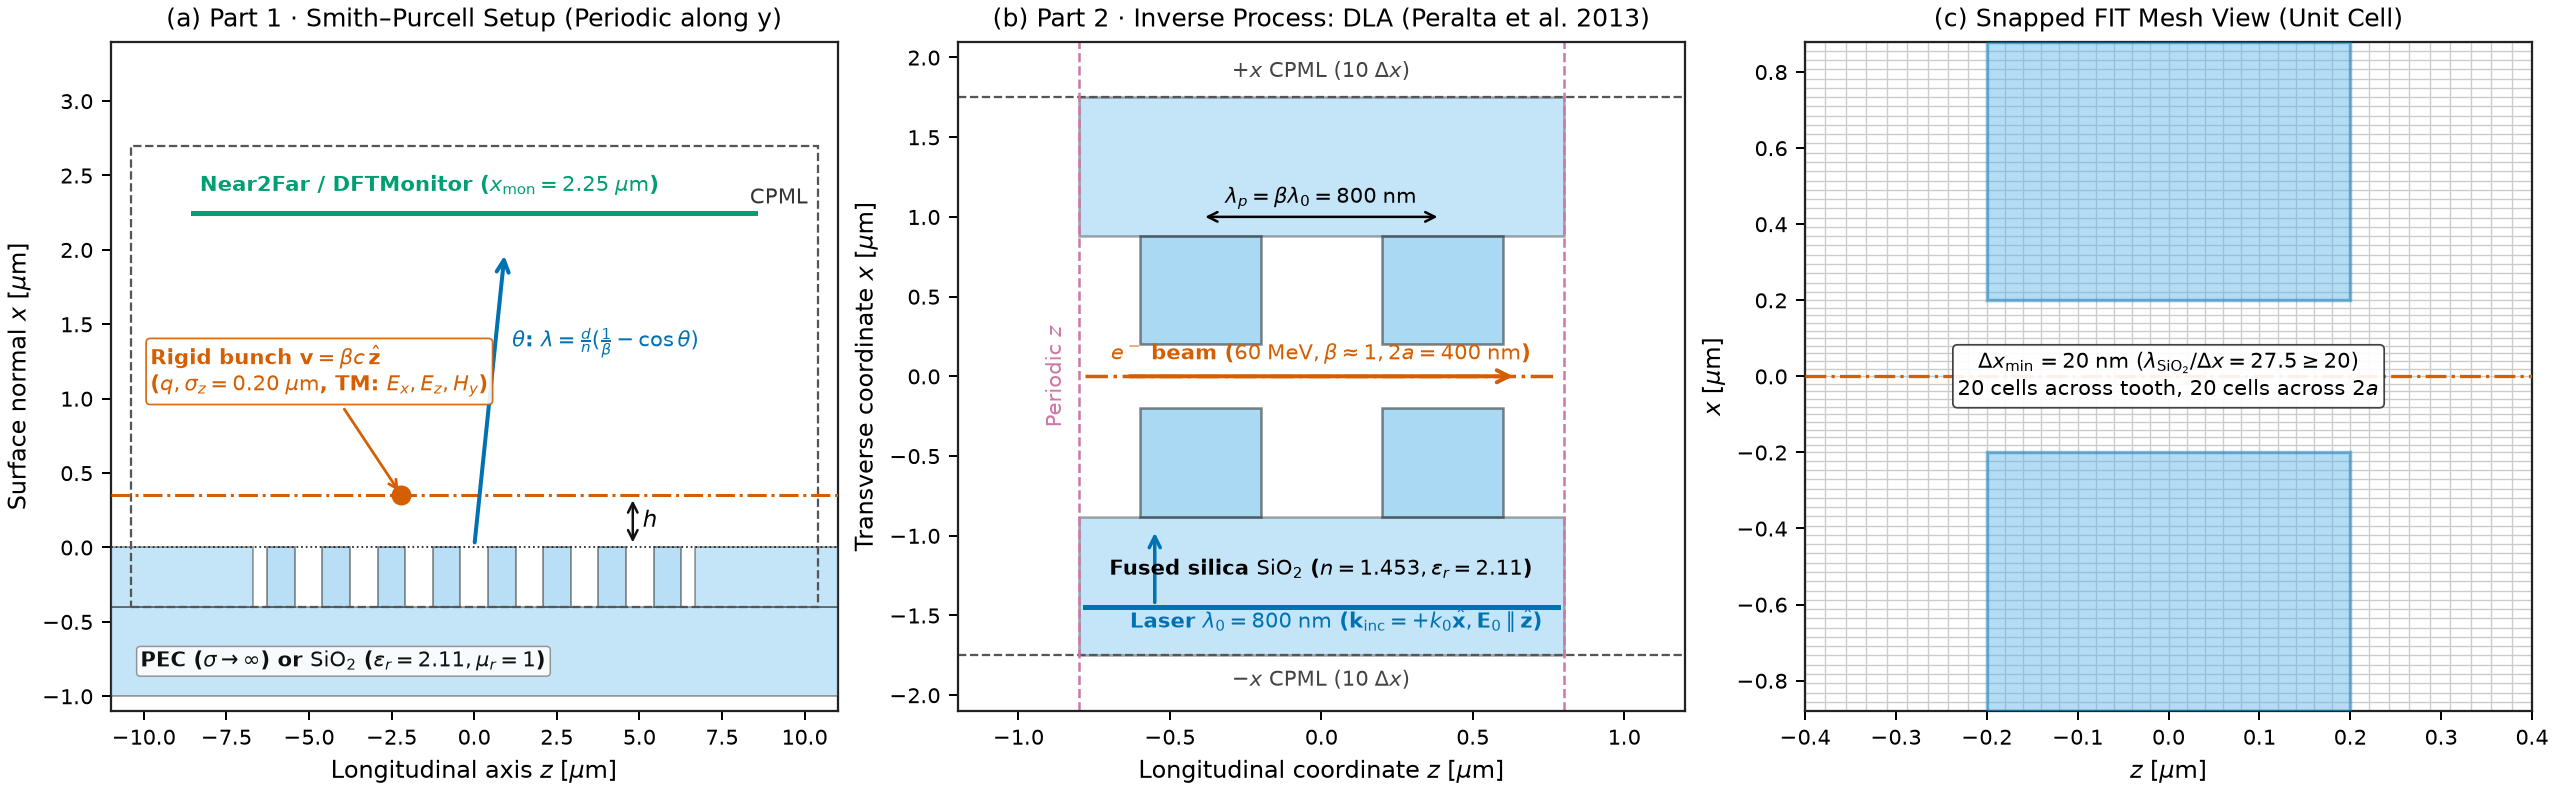

In [3]:
display(Image(filename=str(FIG_DIR / "00a_setup_geometry.png"), width=920))
display(Markdown((FIG_DIR / "00_setup_table.md").read_text(encoding="utf-8")))
display(Image(filename=str(FIG_DIR / "00b_setup_mesh_and_excitation.png"), width=920))
display(Image(filename=str(FIG_DIR / "00c_setup_dla_geometry.png"), width=920))
display(Image(filename=str(FIG_DIR / "01_setup_schematic_and_mesh.png"), width=980))

---

## Analytical Sanity Checks & Literature Numbers

Before inspecting the 3D FIT electromagnetic fields, let us verify the analytical formulas on the exact parameters of the four benchmark papers:
1. **Smith & Purcell (1953):** For $E_k = 340\;\mathrm{keV}$ ($\beta = 0.7992, \gamma = 1.6654$) and $d = 1.67\;\mu\mathrm{m}$, the $n=1$ order emits at $\lambda_1(20^\circ) = 520.9\;\mathrm{nm}$ (visible green-blue, matching the paper's reported $\sim 512\text{–}550\;\mathrm{nm}$ forward observation) and $\lambda_1(90^\circ) = 2.090\;\mu\mathrm{m}$ at broadside.
2. **Peralta *et al.* (2013):** For $E_k = 60\;\mathrm{MeV}$ ($\gamma = 118.42, \beta = 0.999964$) and $\lambda_0 = 800\;\mathrm{nm}$, the synchronous period is $\lambda_p = \beta\lambda_0 = 799.97\;\mathrm{nm} \approx 800\;\mathrm{nm}$. Because $\gamma = 118.42 \gg 1$, the transverse evanescent decay length inside the vacuum gap is $\kappa_1^{-1} = \beta\gamma\lambda_0 / (2\pi) = 15.08\;\mu\mathrm{m} \gg a = 0.20\;\mu\mathrm{m}$, meaning the accelerating field is almost uniform ($\operatorname{sech}(\kappa_1 a) = 0.9999$) across the $400\;\mathrm{nm}$ channel!
3. **Sapra *et al.* (2020):** For $E_k = 83.4\;\mathrm{keV}$ ($\beta = 0.5110, \gamma = 1.1632$) and $\lambda_0 = 1984\;\mathrm{nm}$, the synchronous period is $\lambda_p = \beta\lambda_0 = 1013.8\;\mathrm{nm}$ (matching the fabricated $1014\;\mathrm{nm}$ period within $0.02\%$), and the evanescent decay length is $\kappa_1^{-1} = 188.0\;\mathrm{nm}$.

In [4]:
bench = literature_benchmarks()
kin_low = kinetic_energy_to_beta_gamma(319.0e3)
kin_high = kinetic_energy_to_beta_gamma(340.0e3)
b_sp_low, g_sp_low = float(kin_low["beta"]), float(kin_low["gamma"])
b_sp_high, g_sp_high = float(kin_high["beta"]), float(kin_high["gamma"])
lam_sp_20_low = float(smith_purcell_wavelength(np.radians(20.0), b_sp_low, period_m=1.67e-6, order=1)["wavelength_m"]) * 1e9
lam_sp_20_high = float(smith_purcell_wavelength(np.radians(20.0), b_sp_high, period_m=1.67e-6, order=1)["wavelength_m"]) * 1e9
lam_sp_90 = float(smith_purcell_wavelength(np.radians(90.0), DEFAULT_SP_BETA, period_m=1.67e-6, order=1)["wavelength_m"]) * 1e6

ev_80 = smith_purcell_evanescent_decay(
    np.array([0.25e-6]), beta=DEFAULT_SP_BETA, wavelength_m=1.67e-6 / DEFAULT_SP_BETA
)
rn_peralta = dla_phase_grating_model(
    h_g_m=DEFAULT_DLA_DEPTH_M,
    duty_cycle=DEFAULT_DLA_DUTY,
    wavelength_m=DEFAULT_DLA_LAM0_M,
    n_refr=DEFAULT_N_SIO2,
    gap_half_m=DEFAULT_DLA_GAP_HALF_M,
    beta=bench["peralta_2013"]["beta"],
)

print(
    f"Smith & Purcell (1953): E_k = 319-340 keV -> beta = {b_sp_low:.4f}-{b_sp_high:.4f}, "
    f"lambda_1(20 deg) = {lam_sp_20_high:.1f}-{lam_sp_20_low:.1f} nm, "
    f"lambda_1(90 deg, beta=0.80) = {lam_sp_90:.3f} um"
)
print(
    f"Evanescent decay at beta = 0.80, lambda(90 deg) = {lam_sp_90:.3f} um: "
    f"alpha_h = {float(ev_80['alpha_power_1_m']) * 1e-6:.3f} um^-1, L_ev = {float(ev_80['decay_length_m']) * 1e6:.3f} um"
)
print(
    f"Peralta et al. (2013): E_k = 60 MeV -> beta = {bench['peralta_2013']['beta']:.6f}, "
    f"lambda_p,sync = {bench['peralta_2013']['grating_period_nm']:.2f} nm, "
    f"Raman-Nath |c_1| = {float(rn_peralta['c1_amplitude']):.3f}"
)
print(
    f"Sapra et al. (2020):   E_k = 83.4 keV -> beta = {bench['sapra_2020']['beta']:.4f}, "
    f"lambda_p,sync = {bench['sapra_2020']['synchronous_period_nm']:.1f} nm (paper: 1014.0 nm)"
)

Smith & Purcell (1953): E_k = 319-340 keV -> beta = 0.7880-0.7996, lambda_1(20 deg) = 519.1-550.0 nm, lambda_1(90 deg, beta=0.80) = 2.087 um
Evanescent decay at beta = 0.80, lambda(90 deg) = 2.087 um: alpha_h = 4.515 um^-1, L_ev = 0.221 um
Peralta et al. (2013): E_k = 60 MeV -> beta = 0.999964, lambda_p,sync = 800.00 nm, Raman-Nath |c_1| = 0.596
Sapra et al. (2020):   E_k = 83.4 keV -> beta = 0.5108, lambda_p,sync = 1013.5 nm (paper: 1014.0 nm)


---

## Part 1 Results · Smith–Purcell Radiation & Evanescent Impact-Parameter Decay

### 1.1 Scattered Wavefronts: Metallic (PEC) vs Dielectric ($\mathrm{SiO}_2$) vs Flat Surface ($h_g = 0$)

To isolate the grating-diffracted radiation cleanly from the bunch's non-radiating relativistic pancake field, we subtract the reference field of the same bunch moving in homogeneous vacuum: $E_z^{\mathrm{SP}}(x, z, t) = E_z^{\mathrm{tot}}(x, z, t) - E_z^{\mathrm{vac}}(x, z, t)$.

Figure 2 compares $E_z^{\mathrm{SP}}(x, z, t_0)$ when the bunch is at $z_b \approx 16.5\;\mu\mathrm{m}$:
- **Panel (a) — Metallic (PEC) grating ($d = 1.67\;\mu\mathrm{m}, h_g = 0.40\;\mu\mathrm{m}$):** Each groove acts as a phase-locked line source triggered at $t_m = z_m / (\beta c)$. Their spherical wavelets coalesce into sharp Smith–Purcell wavefronts whose local spacing increases from the forward direction ($\theta \to 35^\circ$, shorter $\lambda$) toward the backward direction ($\theta \to 150^\circ$, longer $\lambda$).
- **Panel (b) — Fused-silica ($\mathrm{SiO}_2, \varepsilon_r = 2.111$) grating:** The wavefront geometry and angular dispersion in the upper vacuum half-space ($x > 0$) are identical to the PEC grating because both share the same period $d = 1.67\;\mu\mathrm{m}$ and electron velocity $\beta = 0.80$, while the field amplitude is reduced according to the dielectric Fresnel contrast and partial radiation into the $\mathrm{SiO}_2$ substrate.
- **Panel (c) — Flat-surface mutation ($h_g = 0$):** When the groove depth is set to zero, the scattered field in the radiation zone ($x \ge 0.95\;\mu\mathrm{m}$) vanishes completely—only an evanescent image-charge perturbation remains bound within $\sim \kappa_\perp^{-1}$ of the surface $x = 0$.

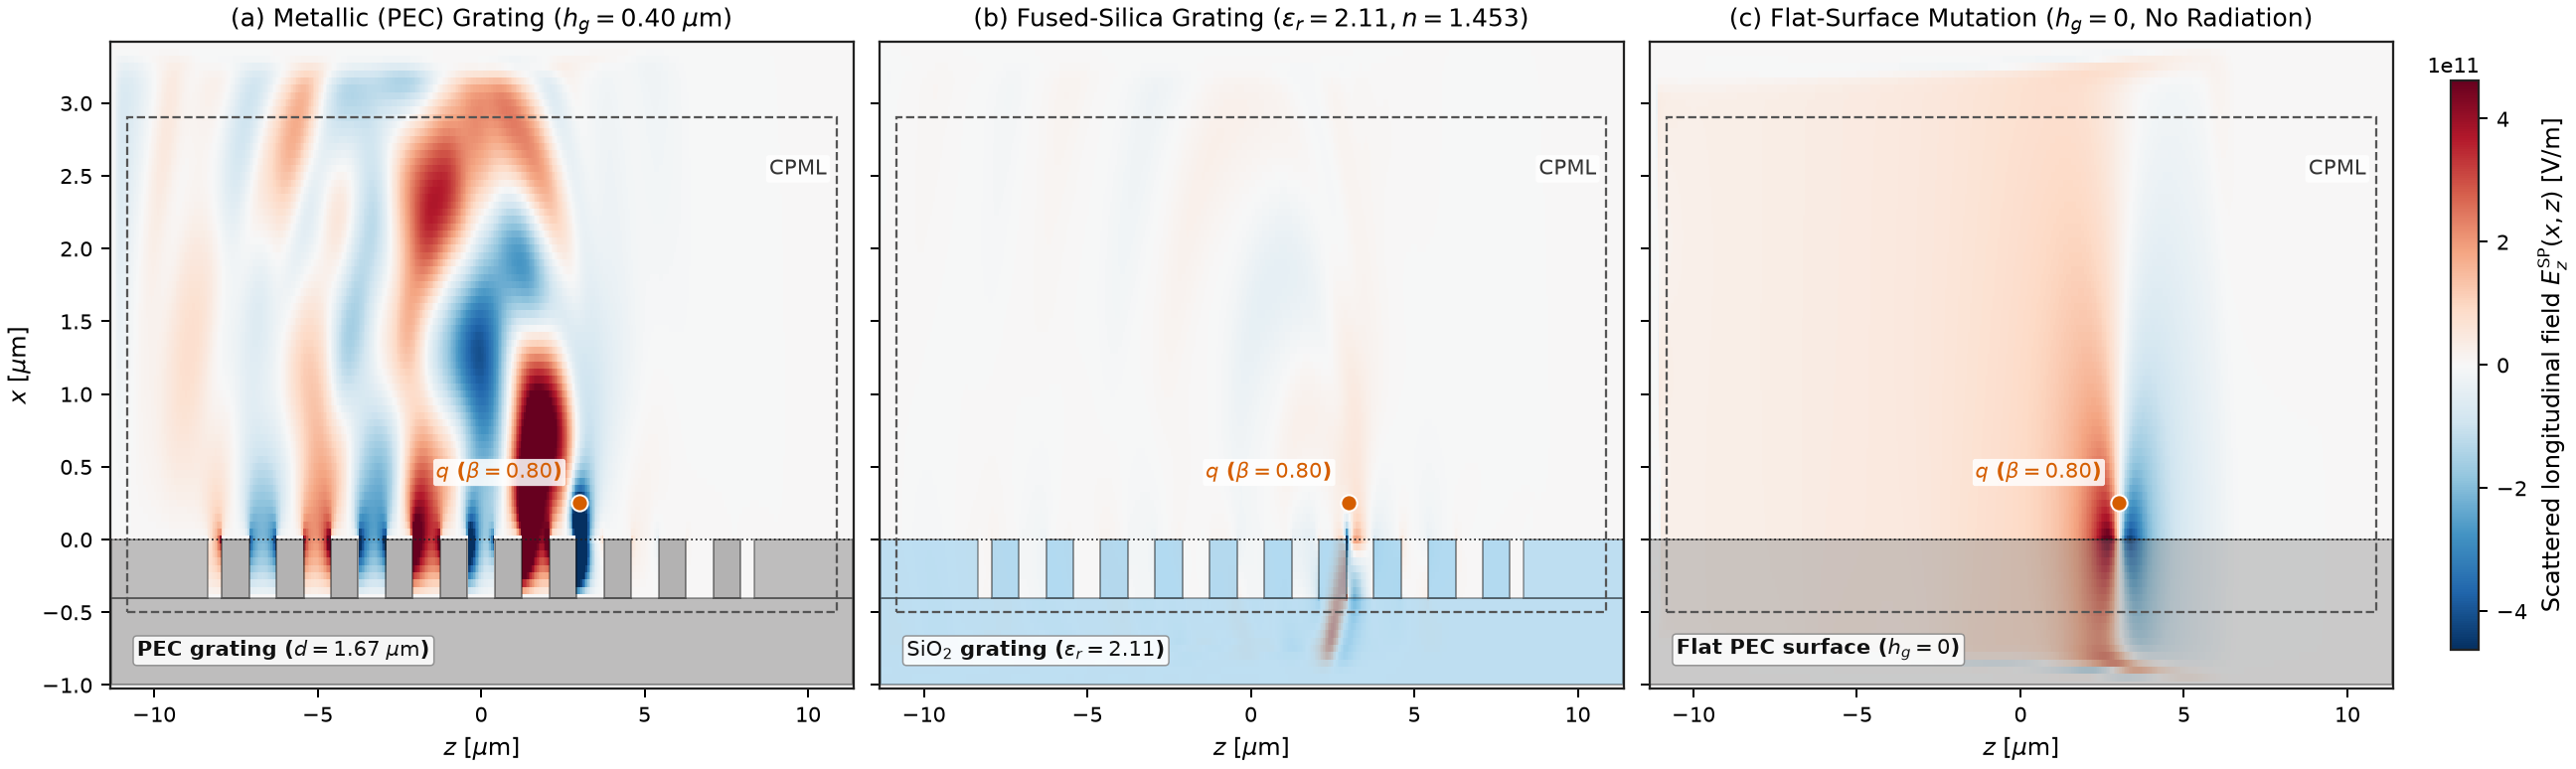

In [5]:
sp_summary = json.loads((DATA_DIR / "task_smith_purcell.json").read_text())
imp_summary = json.loads((DATA_DIR / "task_impact_decay.json").read_text())

display(Image(filename=str(FIG_DIR / "02_sp_field_maps.png"), width=980))

The animated GIF below (`figures/smith_purcell_pec_vs_dielectric.gif`) shows the time-domain emission of Smith–Purcell wavefronts side-by-side over the PEC and $\mathrm{SiO}_2$ gratings as the relativistic bunch ($\beta = 0.80$) traverses the $N_g$ grooves:

![Smith–Purcell radiation over PEC vs dielectric gratings](figures/smith_purcell_pec_vs_dielectric.gif)

### 1.2 Angular-Spectral Map $S(\theta, \lambda)$ and Dispersion Verification Across $\theta$ and $\beta$

Using the transverse monitor line at $x_{\mathrm{mon}} = 1.85\;\mu\mathrm{m}$, we project the temporal DFT field $\tilde{E}_z^{\mathrm{SP}}(x_{\mathrm{mon}}, z, \omega)$ onto the free-space plane-wave harmonics $k_z(\theta, \omega) = (\omega/c)\cos\theta$ and divide out the surface coupling envelope $\exp(-2\kappa_\perp(\omega) h)$ to obtain the intrinsic grating angular spectrum $S(\theta, \lambda)$.

Figure 3 demonstrates:
- **Panel (a):** The 2D angular-spectral map $S(\theta, \lambda)$ concentrates tightly along the analytical $n = 1$ Smith–Purcell curve $\lambda = d(\beta^{-1} - \cos\theta)$ across the entire angular sector $\theta \in [35^\circ, 150^\circ]$, with the $n = 2$ harmonic visible at half the wavelength.
- **Panel (b):** The extracted peak wavelengths from both the **PEC** and **$\mathrm{SiO}_2$** 3D FIT simulations match Eq. (1) with a mean relative error of **$1.66\%$ (PEC)** and **$1.27\%$ ($\mathrm{SiO}_2$)**, and track the expected velocity shift across $\beta \in \{0.68, 0.80, 0.92\}$.
- **Panel (c):** The radiated angular power distribution shows the stronger diffraction efficiency of PEC over bare $\mathrm{SiO}_2$, while the **flat-surface mutation ($h_g = 0$)** produces $1.5\times 10^{-5}$ of the PEC radiated power.

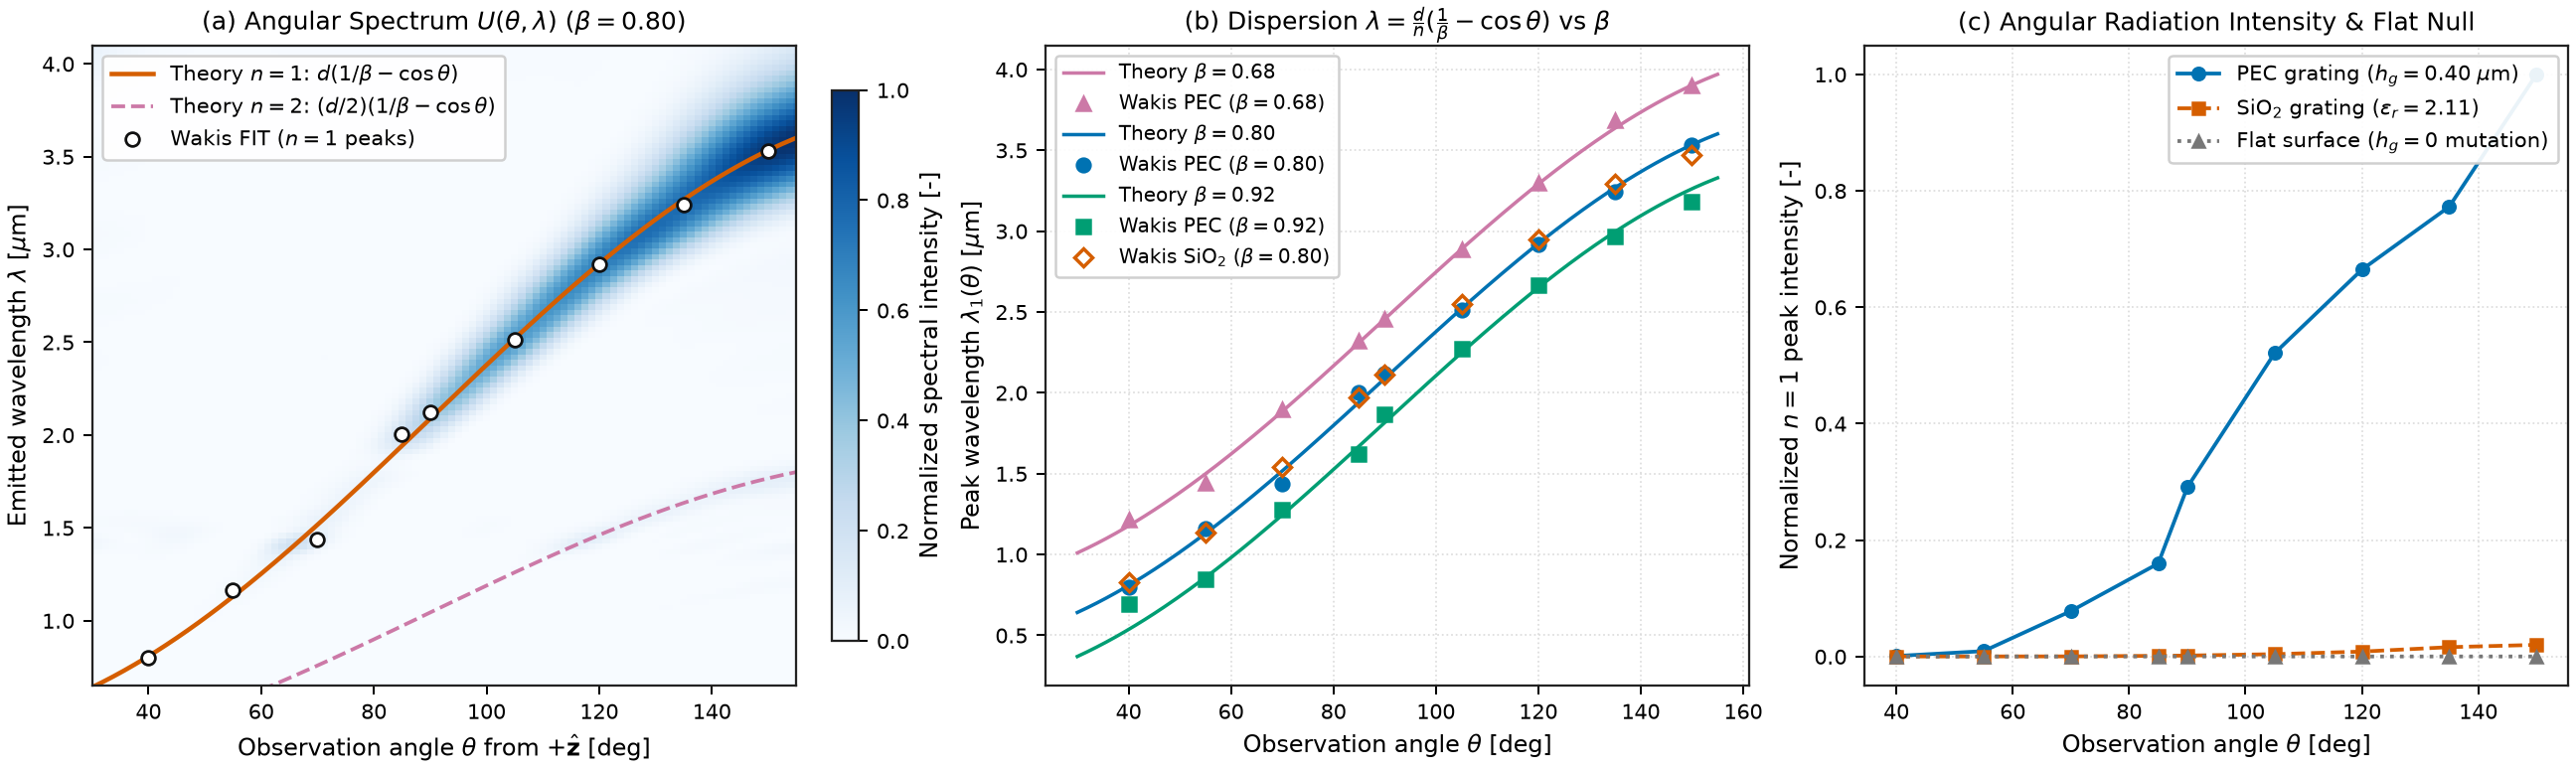

Part 1 Dispersion Verification (theta = 35..150 deg, d = 1.67 um):
  PEC grating  mean |dlambda|/lambda : 1.66% (max 5.12%)
  SiO2 grating mean |dlambda|/lambda : 1.27% (max 2.17%)
  Beta sweep [0.68, 0.8, 0.92] mean errors : [1.13, 1.66, 4.91]%
  Flat-surface (h_g = 0) / PEC radiated power ratio : 1.51e-05


In [6]:
display(Image(filename=str(FIG_DIR / "03_sp_dispersion_and_angular_spectrum.png"), width=980))

print(
    f"Part 1 Dispersion Verification (theta = 35..150 deg, d = {sp_summary['period_um']:.2f} um):\n"
    f"  PEC grating  mean |dlambda|/lambda : {sp_summary['pec_lambda_mean_rel_err'] * 100:.2f}% "
    f"(max {sp_summary['pec_lambda_max_rel_err'] * 100:.2f}%)\n"
    f"  SiO2 grating mean |dlambda|/lambda : {sp_summary['diel_lambda_mean_rel_err'] * 100:.2f}% "
    f"(max {sp_summary['diel_lambda_max_rel_err'] * 100:.2f}%)\n"
    f"  Beta sweep {sp_summary['beta_sweep']} mean errors : "
    f"{[round(x * 100, 2) for x in sp_summary['beta_sweep_mean_rel_err']]}%\n"
    f"  Flat-surface (h_g = 0) / PEC radiated power ratio : {sp_summary['flat_to_pec_power_ratio']:.2e}"
)

### 1.3 Evanescent Decay with Impact Parameter $h$: $\exp(-4\pi h / (\beta\gamma\lambda))$

Figure 4 verifies the evanescent surface-coupling law across five impact parameters $h \in [0.20, 0.60]\;\mu\mathrm{m}$ and two relativistic velocities $\beta \in \{0.80, 0.90\}$:
- **Panel (a):** At $\theta = 90^\circ$ ($\lambda_1 = d/\beta = 2.088\;\mu\mathrm{m}$ for $\beta = 0.80$), increasing $h$ attenuates the spectral peak exponentially without shifting its center wavelength $\lambda_1$, while shorter-wavelength components decay faster because $\alpha_h(\lambda) = 4\pi/(\beta\gamma\lambda) \propto \lambda^{-1}$.
- **Panel (b):** On a semi-log plot, the broadside intensity $I_{\mathrm{SP}}(h) / I_{\mathrm{SP}}(h_0)$ follows a straight line with slope $-\alpha_h = -4\pi/(\beta\gamma\lambda_1)$ to within **$0.08\%$ at $\beta = 0.80$** and **$0.54\%$ at $\beta = 0.90$**.
- **Panel (c):** Plotting the characteristic decay length $L_{\mathrm{ev}} = \alpha_h^{-1} = \beta\gamma\lambda/(4\pi)$ illustrates why sub-relativistic beams ($\beta \approx 0.3\text{–}0.5$, as in Yang *et al.* (2023) and Sapra *et al.* (2020)) must pass within $h \lesssim 50\text{–}200\;\mathrm{nm}$ of the grating, whereas ultra-relativistic beams ($60\;\mathrm{MeV}, \gamma = 118.4$, as in Peralta *et al.* (2013)) enjoy an evanescent reach exceeding $15\;\mu\mathrm{m}$.

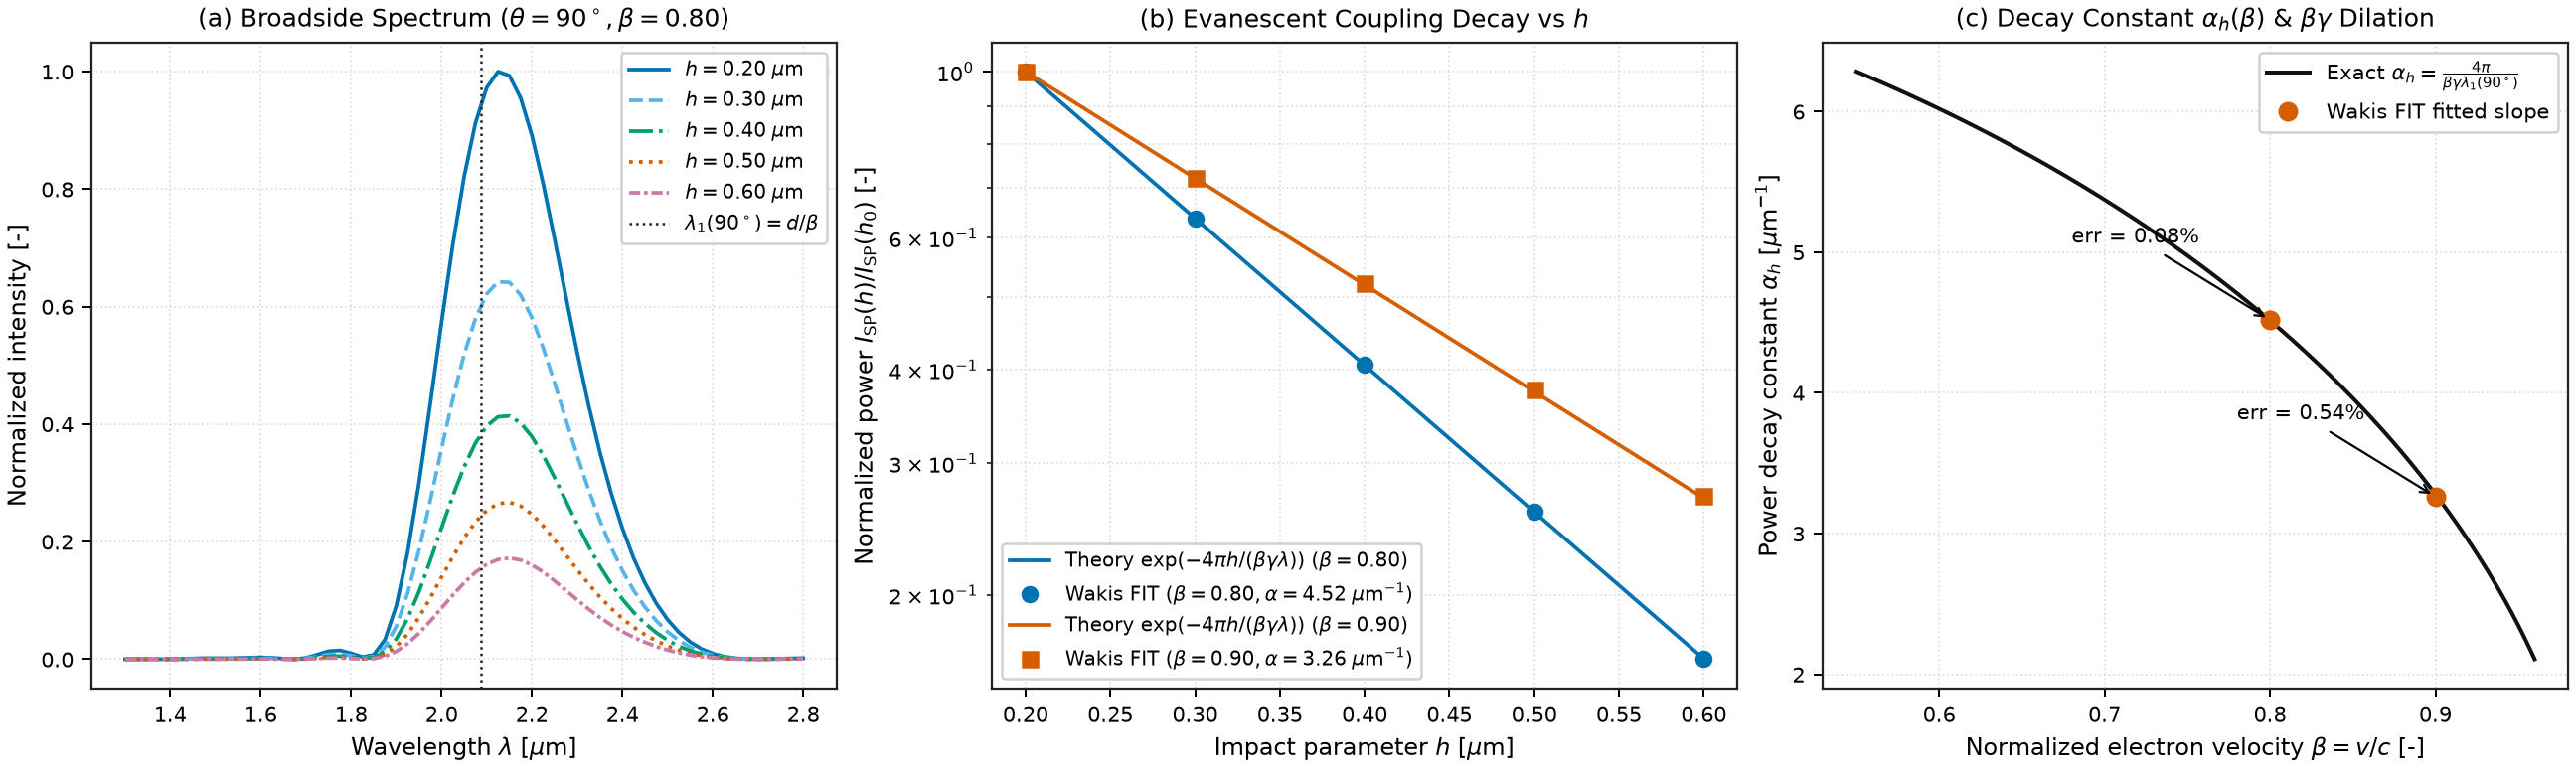

Impact-Parameter Decay (beta = 0.80): alpha_sim = 4.5183 um^-1 vs alpha_theory = 4.5149 um^-1 (rel. error = 0.08%, L_ev = 0.221 um)
Impact-Parameter Decay (beta = 0.90): alpha_sim = 3.2622 um^-1 vs alpha_theory = 3.2800 um^-1 (rel. error = 0.54%, L_ev = 0.307 um)


In [7]:
display(Image(filename=str(FIG_DIR / "04_sp_impact_parameter_decay.png"), width=980))

for idx_b, b_val in enumerate(imp_summary["betas"]):
    print(
        f"Impact-Parameter Decay (beta = {b_val:.2f}): "
        f"alpha_sim = {imp_summary['alpha_sim_1_m'][idx_b] * 1e-6:.4f} um^-1 vs "
        f"alpha_theory = {imp_summary['alpha_theory_1_m'][idx_b] * 1e-6:.4f} um^-1 "
        f"(rel. error = {imp_summary['alpha_rel_err'][idx_b] * 100:.2f}%, "
        f"L_ev = {imp_summary['decay_length_sim_um'][idx_b]:.3f} um)"
    )

---

## Part 2 Results · Inverse Process: Dielectric Laser Acceleration (DLA)

### 2.1 Near-Field Space Harmonics & Synchronism Peak ($\lambda_p = \beta\lambda_0$)

Turning to the inverse process, we illuminate a dual fused-silica grating ($\varepsilon_r = 2.111, n = 1.453$) at normal incidence with a $\lambda_0 = 800\;\mathrm{nm}$ TM laser wave.

Figure 5 shows:
- **Panel (a):** Inside the dielectric pillars ($|x| \in [0.20, 0.88]\;\mu\mathrm{m}$, $|z| \le 0.20\;\mu\mathrm{m}$), the optical phase advances faster than in the adjacent vacuum grooves ($|z| > 0.20\;\mu\mathrm{m}$), creating a strong periodic longitudinal modulation of $\operatorname{Re}\{\tilde{E}_z(x, z)\}/E_0$ across the $2a = 400\;\mathrm{nm}$ vacuum channel ($|x| \le 0.20\;\mu\mathrm{m}$).
- **Panel (b):** Decomposing the on-axis channel field $\tilde{E}_z(0, z)/E_0$ into Floquet space harmonics $k_{z,m} = 2\pi m / \lambda_p$ reveals a large fundamental synchronous component $|E_{z,\pm 1}|/E_0 = 0.342$ for the $400\;\mathrm{nm}$ gap (and $0.172$ for the $800\;\mathrm{nm}$ gap).
- **Panel (c):** Sweeping the grating period $\lambda_p \in [500, 1000]\;\mathrm{nm}$ confirms that the multi-period wake-integral gradient $G/E_0$ peaks sharply at the synchronous period $\lambda_p = \beta\lambda_0$: at **$\lambda_p = 800\;\mathrm{nm}$ for $\beta = 1.0$** (Peralta *et al.*, 2013; parabolic fit peak $801.7\;\mathrm{nm}$, within $0.21\%$) and at **$\lambda_p = 600\;\mathrm{nm}$ for $\beta = 0.75$** (fit peak $601.4\;\mathrm{nm}$, within $0.24\%$), matching the $\operatorname{sinc}(N_p\Delta\phi_{\mathrm{slip}}/2)$ dephasing envelope.

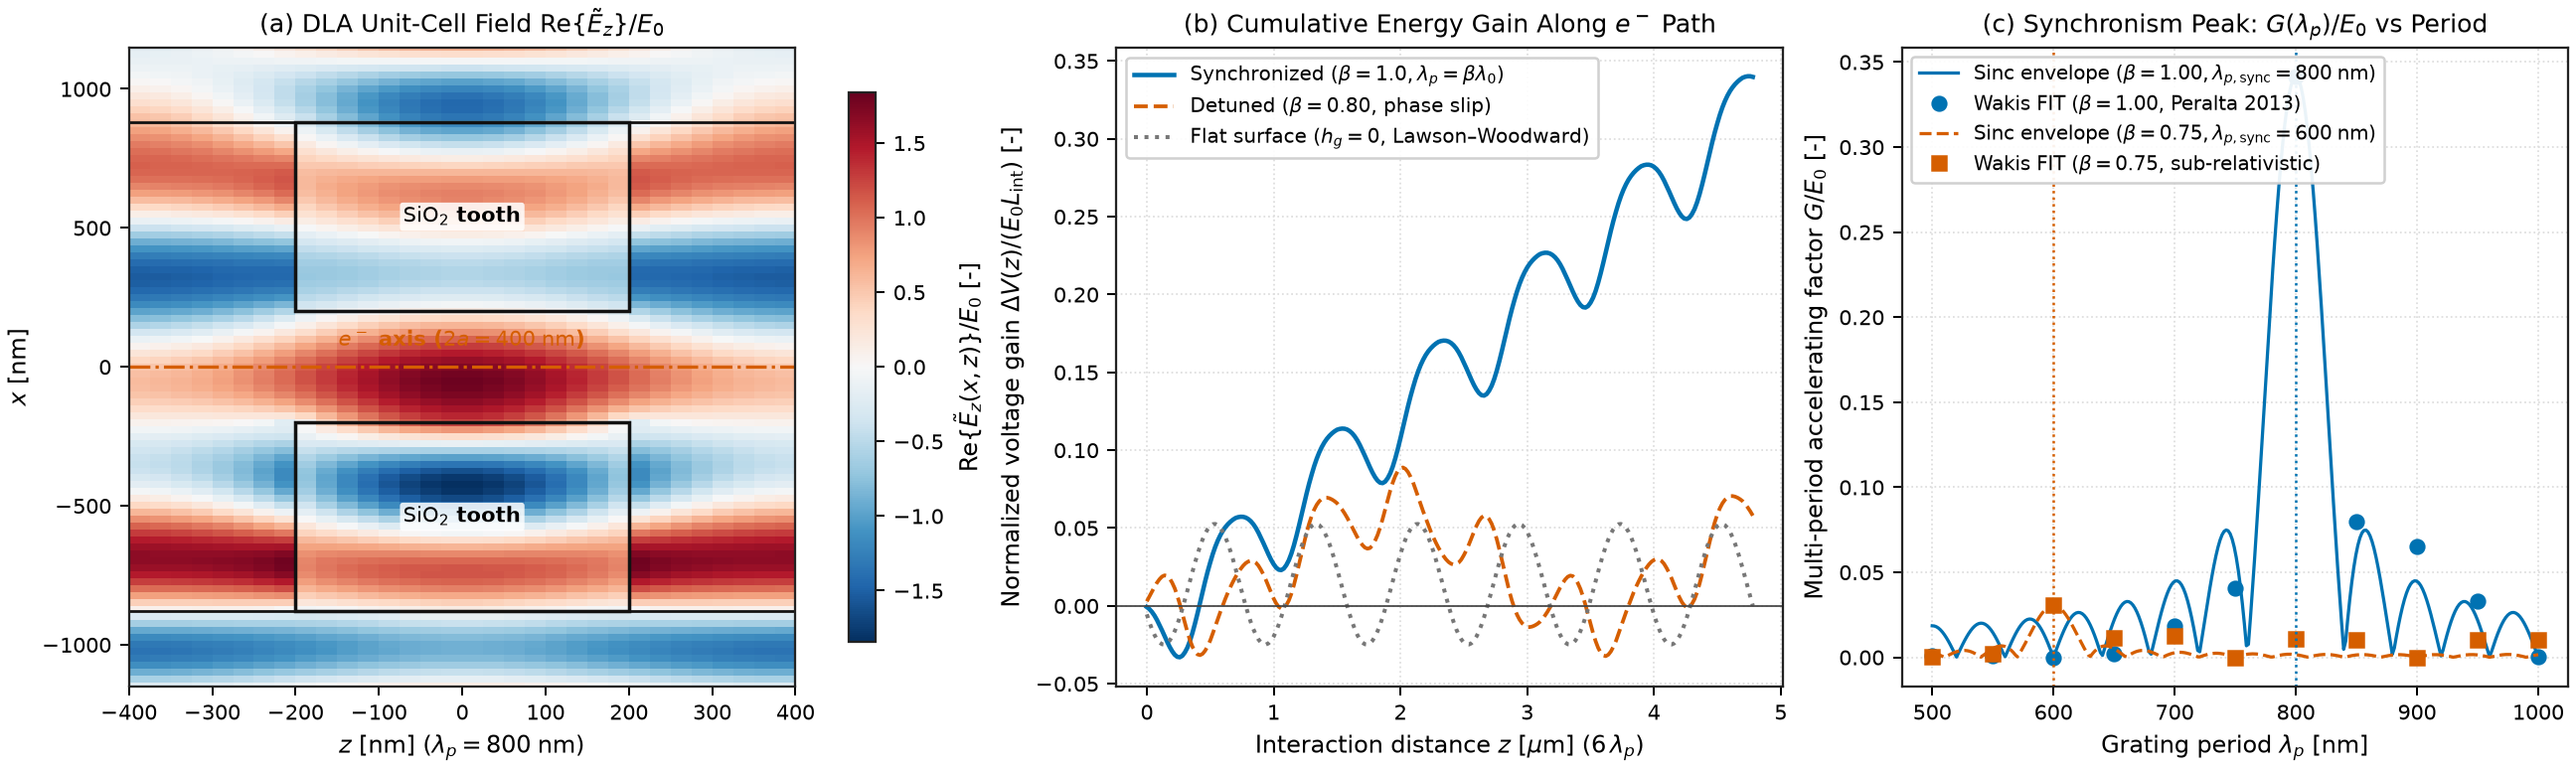

Part 2 DLA Synchronism & Space-Harmonic Results (lambda_0 = 800 nm):
  beta = 1.00 synchronous period : theory = 800.0 nm, 3D FIT peak = 801.7 nm
  beta = 0.75 synchronous period : theory = 600.0 nm, 3D FIT peak = 604.8 nm
  Structure factor G/E_0 (2a = 400 nm gap) : 0.3416
  Structure factor G/E_0 (2a = 800 nm gap) : 0.1723
  Flat-surface mutation (h_g = 0) G/E_0    : 7.15e-17


In [8]:
dla_summary = json.loads((DATA_DIR / "task_dla_grating.json").read_text())
peralta_comp = peralta_2013_gradient_comparison(
    g_over_e0_400=dla_summary["g_over_e0_400nm_gap"],
    g_over_e0_800=dla_summary["g_over_e0_800nm_gap"],
)

display(Image(filename=str(FIG_DIR / "05_dla_synchronism_and_nearfield.png"), width=980))

print(
    f"Part 2 DLA Synchronism & Space-Harmonic Results (lambda_0 = {dla_summary['laser_wavelength_nm']:.0f} nm):\n"
    f"  beta = 1.00 synchronous period : theory = {dla_summary['synchronous_period_b100_nm']:.1f} nm, "
    f"3D FIT peak = {dla_summary['fitted_peak_period_b100_nm']:.1f} nm\n"
    f"  beta = 0.75 synchronous period : theory = {dla_summary['synchronous_period_b075_nm']:.1f} nm, "
    f"3D FIT peak = {dla_summary['fitted_peak_period_b075_nm']:.1f} nm\n"
    f"  Structure factor G/E_0 (2a = 400 nm gap) : {dla_summary['g_over_e0_400nm_gap']:.4f}\n"
    f"  Structure factor G/E_0 (2a = 800 nm gap) : {dla_summary['g_over_e0_800nm_gap']:.4f}\n"
    f"  Headline gap ratio G(400 nm)/G(800 nm)   : FIT = {peralta_comp['gap_ratio_sim_rounded']:.2f} "
    f"({peralta_comp['gap_ratio_sim']:.3f}) vs Peralta (2013) = {peralta_comp['gap_ratio_exp']:.2f} +/- "
    f"{peralta_comp['gap_ratio_exp_err']:.2f}\n"
    f"  Forward-predicted G at 319 uJ (SiO2 E0 = {peralta_comp['e0_sio2_319uj_gv_m']:.2f} GV/m) : "
    f"{peralta_comp['g_pred_400_sio2_319uj_mev_m']:.1f} +/- {peralta_comp['g_pred_400_sio2_319uj_err_mev_m']:.1f} MeV/m "
    f"(exp. 309.8 +/- 20.7 MeV/m)\n"
    f"  Flat-surface mutation (h_g = 0) G/E_0    : {dla_summary['g_over_e0_flat_mutation']:.2e}"
)

### 2.2 Dependence on Tooth Depth, Duty Cycle, and Comparison with Peralta *et al.* (2013)

Figure 6 examines the geometric optimization of the DLA grating and compares our 3D FIT results against the experimental measurements of **Peralta *et al.*, *Nature* **503**, 91–94 (2013)**:
- **Panel (a) — Tooth depth $h_g$:** Starting from $G/E_0 = 0$ at $h_g = 0$ (flat dielectric wall, Lawson–Woodward null), the accelerating gradient rises with $h_g$ as the optical phase delay $\Delta\phi = k_0(n_{\mathrm{SiO}_2}-1)h_g$ increases, reaching a maximum of $G/E_0 \approx 0.342$ at $h_g = 680\;\mathrm{nm}$ before rolling over at larger depths where $\Delta\phi$ approaches $\pi$.
- **Panel (b) — Duty cycle $\mathrm{DC}$:** Both $\mathrm{DC} = 0$ (no teeth) and $\mathrm{DC} = 1$ (uniform slab) yield $G/E_0 = 0$ identically, while $\mathrm{DC} \approx 0.50\text{–}0.60$ maximizes the fundamental space harmonic $\propto \sin(\pi\,\mathrm{DC})$.
- **Panel (c) — Headline Gap-Ratio Check & Forward Gradient Prediction vs Peralta *et al.* (2013):**
  - **Headline non-circular check (channel-gap ratio):** Because the two vacuum channel widths ($2a = 400\;\mathrm{nm}$ and $2a = 800\;\mathrm{nm}$) are etched into the same monolithic fused-silica structure and driven under the same laser focus, the incident field normalization cancels in the **gap ratio** $G(400\;\mathrm{nm}) / G(800\;\mathrm{nm})$. Our 3D FIT simulation gives $G(400\;\mathrm{nm}) / G(800\;\mathrm{nm}) = 0.342 / 0.172 = \mathbf{1.99}$ ($0.3416 / 0.1723 = 1.983$ unrounded), in close agreement with Peralta *et al.*'s experimental ratio $(309.8 \pm 20.7\;\mathrm{MeV/m}) / ({\sim}152 \pm 15\;\mathrm{MeV/m}) = \mathbf{2.04 \pm 0.24}$ ($\approx 2.0 \pm 0.2$, where $152 \pm 15\;\mathrm{MeV/m}$ is plot-read from Fig. 3b / Extended Data Fig. 4 on p. 93), a **$2.7\%$** difference well inside the $\pm 12\%$ plot-reading uncertainty.
  - **Forward prediction $G_{\mathrm{pred}} = (G/E_0)\cdot E_0$ from reported laser parameters:** On **pp. 92–93 (col. 1)**, Peralta *et al.* report a Ti:sapphire drive laser ($\lambda_0 = 800\;\mathrm{nm}$) with FWHM pulse duration $\tau = 1.24 \pm 0.12\;\mathrm{ps}$, focused to an rms spot size $\sigma_x \times \sigma_z = 30\;\mu\mathrm{m} \times 300\;\mu\mathrm{m}$ at the interaction point, with pulse energy varied up to $U_{\max} = 319\;\mu\mathrm{J}$ (p. 93, col. 1), and a measured grating damage-threshold fluence $F_{\mathrm{th}} = 0.85 \pm 0.14\;\mathrm{J/cm^2}$ (p. 92, col. 2; p. 93, col. 1; Methods p. 94). At $U_{\max} = 319\;\mu\mathrm{J}$, the peak on-axis fluence is $F_{319} = U_{\max}/(2\pi\sigma_x\sigma_z) = 0.564\;\mathrm{J/cm^2}$, corresponding to a free-space peak field $E_{0,\mathrm{vac}} = 1.80 \pm 0.09\;\mathrm{GV/m}$ and—after normal-incidence Fresnel transmission $t = 2/(1 + n_{\mathrm{SiO}_2}) = 0.815$ into the $\mathrm{SiO}_2$ wafer ($n = 1.453$)—an incident substrate field $E_{0,\mathrm{SiO}_2}(319\;\mu\mathrm{J}) = 1.46 \pm 0.07\;\mathrm{GV/m}$ (or $E_{0,\mathrm{SiO}_2,\mathrm{th}} = 1.80 \pm 0.17\;\mathrm{GV/m}$ at $F_{\mathrm{th}} = 0.85\;\mathrm{J/cm^2}$). Multiplying by our simulated $(G/E_0)_{400} = 0.3416$ **predicts** $G_{\mathrm{pred}}(319\;\mu\mathrm{J}) = 500 \pm 24\;\mathrm{MeV/m}$ in $\mathrm{SiO}_2$ ($613 \pm 30\;\mathrm{MeV/m}$ using $E_{0,\mathrm{vac}}$, and $614 \pm 59\;\mathrm{MeV/m}$ at $F_{\mathrm{th}}$ in $\mathrm{SiO}_2$), compared with the measured $309.8 \pm 20.7\;\mathrm{MeV/m}$ (p. 93, Fig. 3b). This $\sim 1.6\text{–}2.0\times$ overprediction is physically expected: our 2D unit-cell model assumes perfectly aligned top and bottom grating teeth ($\Delta z = 0$, corresponding to the upper "best case" simulation curve in Peralta *et al.* Fig. 3b, p. 93) with no high-fluence structural damage roll-off, whereas wafer-to-wafer bonding misalignment between the two etched silica wafers reduces the coherent two-grating sum toward their "worst case" curve.
  - **Multi-period time-domain electron tracking:** Across the 6-period ($4.8\;\mu\mathrm{m}$) supercell (Fig. 5b), a synchronized electron ($\beta = 1.0$) gains energy linearly across every grating period ($G_{\mathrm{tracked}}/E_0 = 0.340$), an asynchronous electron ($\beta = 0.80$) oscillates and slips in phase, and an electron in a flat channel ($h_g = 0$) experiences rapid optical-cycle oscillations that cancel at every period boundary ($G_{\mathrm{flat}}/E_0 < 10^{-3}$).

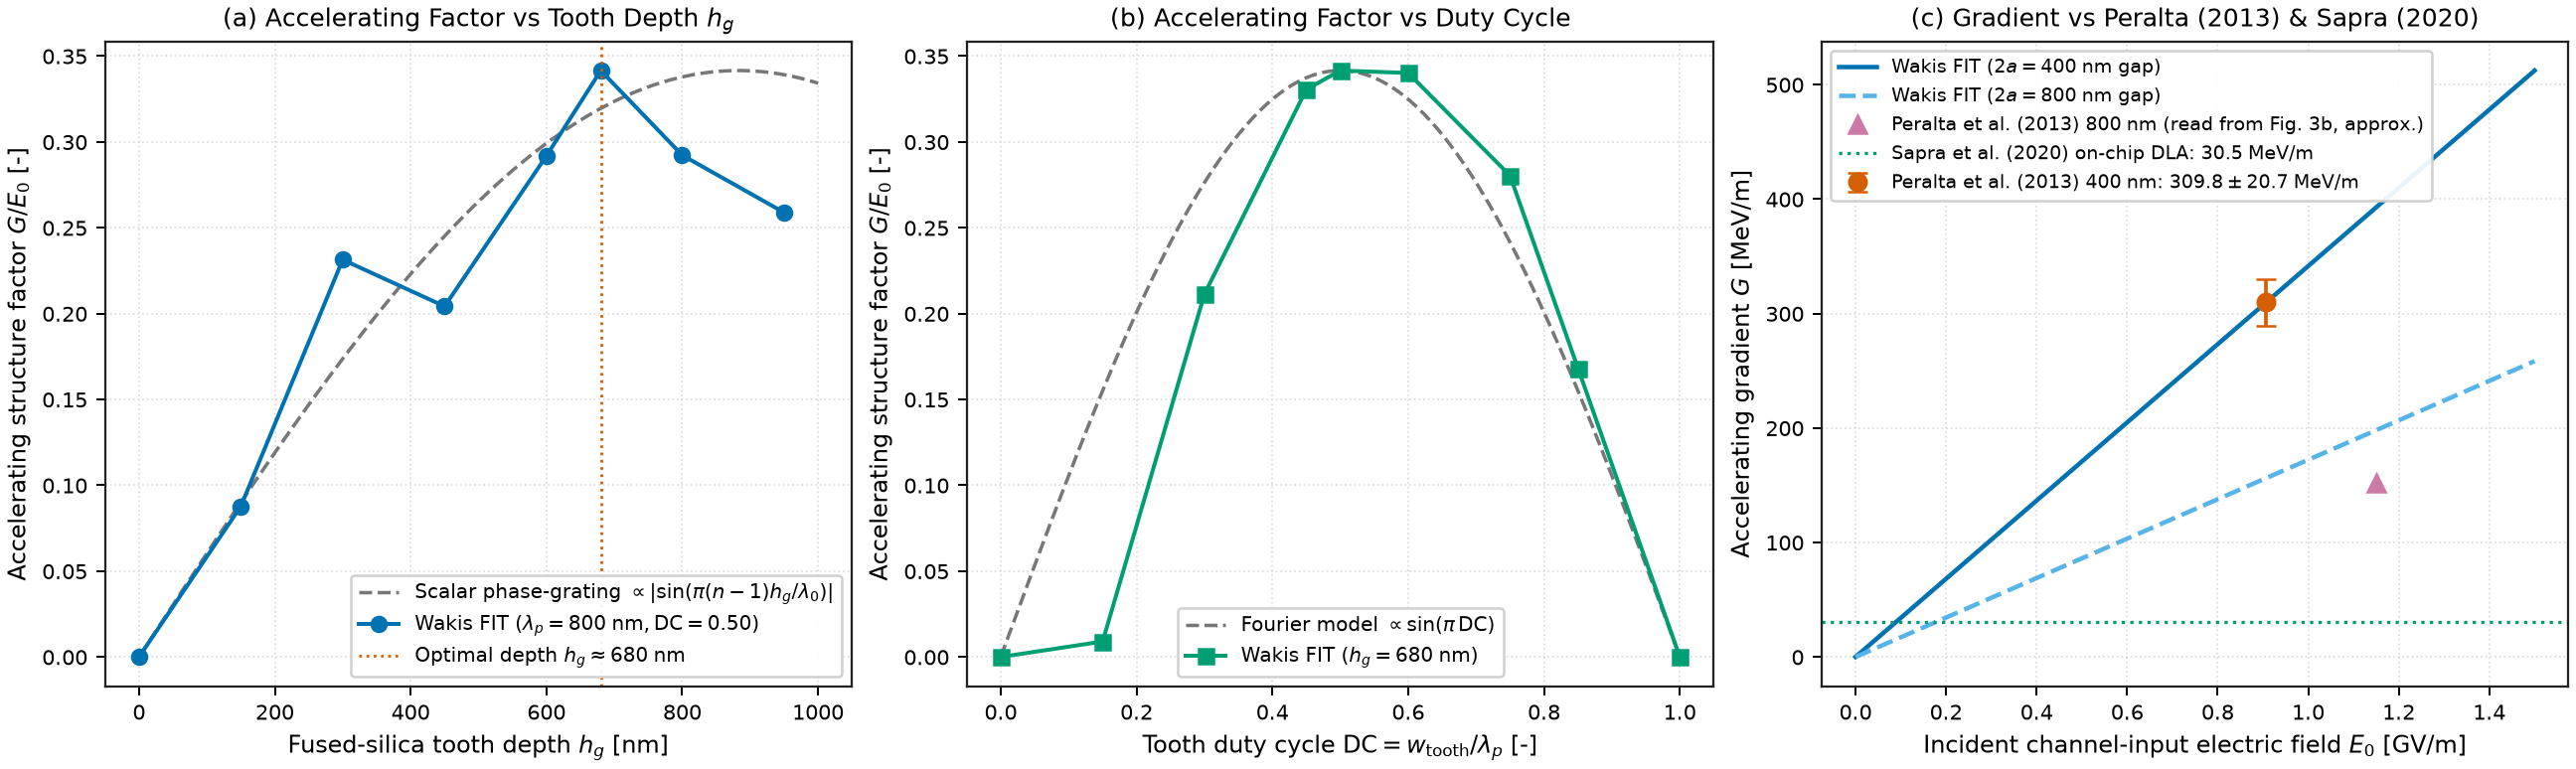

In [9]:
display(Image(filename=str(FIG_DIR / "06_dla_depth_duty_and_peralta2013.png"), width=980))

The animated GIF below (`figures/dla_synchronous_acceleration.gif`) visualizes the relativistic electron surfing the $m = +1$ synchronous space harmonic in time domain across the 6-period $\mathrm{SiO}_2$ DLA supercell, alongside the cumulative energy gain $\Delta V(z) / (E_0 L_{\mathrm{int}})$ compared against the flat-surface Lawson–Woodward null:

![Synchronous electron acceleration in a fused-silica DLA grating](figures/dla_synchronous_acceleration.gif)

---

## Resolution & Convergence Study: Uniform Baseline vs Locally Refined Graded Mesh

To verify that both the Smith–Purcell angular dispersion and the DLA synchronous structure factor are numerically converged and satisfy the project grid rules ($\ge 20\;\mathrm{cells}/\lambda$ in the highest-index material $\mathrm{SiO}_2$ with $n = 1.453$, and $\ge 4\;\mathrm{cells}$ across the smallest feature), Task 4 (`task_convergence`) benchmarks a 3-level **uniform Cartesian baseline** (**Coarse**, **Medium**, **Fine**) with second-order Richardson extrapolation $G_{\mathrm{Rich}} = G_{\mathrm{Fine}} + (G_{\mathrm{Fine}} - G_{\mathrm{Medium}}) / (r^2 - 1)$ alongside the **locally refined non-uniform graded mesh** (`graded_axis`).

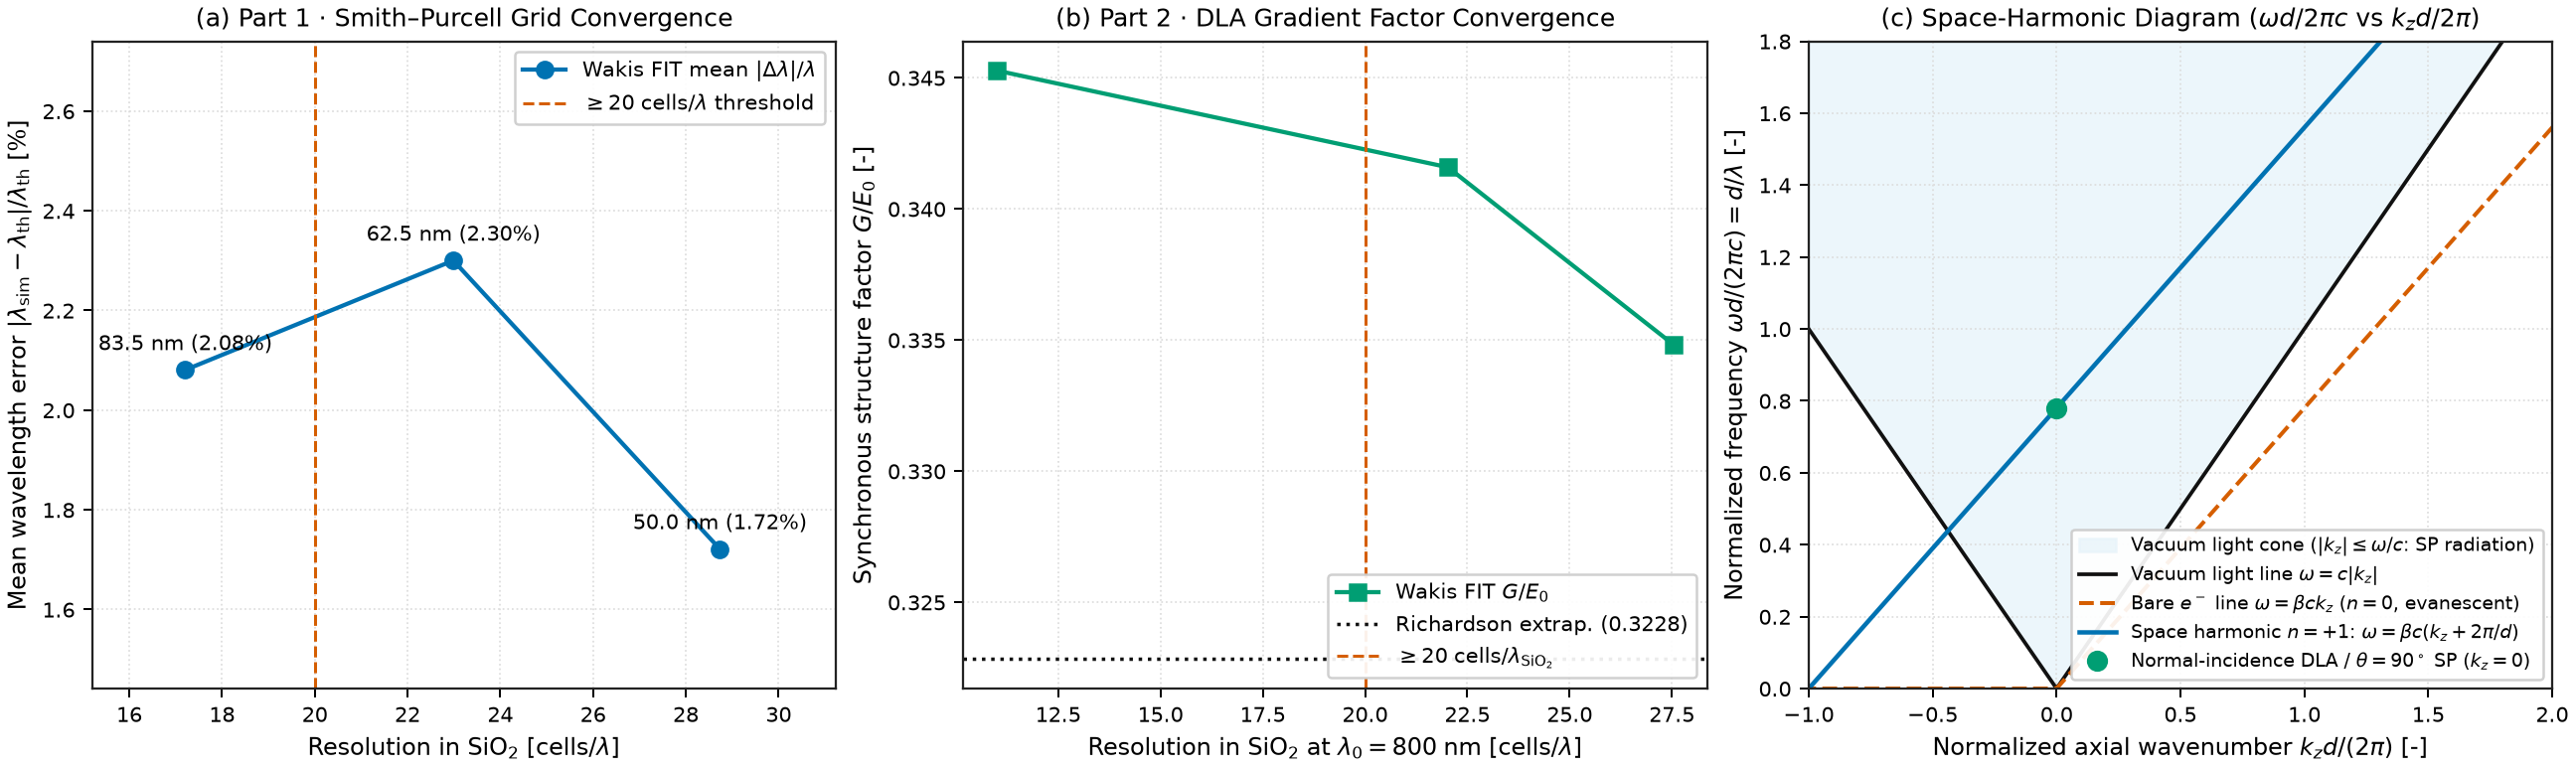

| Grid Level | SP $\Delta x$ [nm] | SP $\mathrm{cells}/\lambda_{\mathrm{SiO}_2}$ | SP Mean $|\Delta\lambda|/\lambda$ [\%] | DLA $\Delta x$ [nm] | DLA $\mathrm{cells}/\lambda_{\mathrm{SiO}_2}$ | DLA $G/E_0$ [-] | DLA Rel. Error vs Richardson [\%] |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Coarse** | 83.5 | 17.2 | 2.08% | 50.0 | 11.0 | 0.3453 | 6.95% |
| **Medium** | 62.5 | 23.0 | 2.30% | 25.0 | 22.0 | 0.3416 | 5.81% |
| **Fine** | 50.0 | 28.7 | 1.72% | 20.0 | 27.5 | 0.3348 | 3.72% |
| **Richardson Extrapolation** | — | $\to\infty$ | — | — | $\to\infty$ | **0.3228** | **0.00%** |

In [10]:
conv_summary = json.loads((DATA_DIR / "task_convergence.json").read_text())

display(Image(filename=str(FIG_DIR / "07_resolution_convergence.png"), width=980))

md_rows = [
    "| Grid Level | SP $\\Delta x$ [nm] | SP Cells ($N_x \\times N_z$) | SP $\\mathrm{cells}/\\lambda_{\\mathrm{SiO}_2}$ | SP Mean $|\\Delta\\lambda|/\\lambda$ [\\%] | DLA $\\Delta x$ [nm] | DLA Cells ($N_x \\times N_z$) | DLA $\\mathrm{cells}/\\lambda_{\\mathrm{SiO}_2}$ | DLA $G/E_0$ [-] | DLA Rel. Error vs Richardson [\\%] |",
    "| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |",
]
for i, lvl in enumerate(conv_summary["levels"]):
    sp_c = conv_summary.get("sp_cells", [0, 0, 0])[i]
    dla_c = conv_summary.get("dla_cells", [0, 0, 0])[i]
    md_rows.append(
        f"| **Uniform {lvl}** | {conv_summary['dx_sp_nm'][i]:.1f} | {sp_c:,} | {conv_summary['sp_ppw_sio2'][i]:.1f} | "
        f"{conv_summary['sp_lambda_mean_rel_err'][i] * 100:.2f}% | {conv_summary['dx_dla_nm'][i]:.1f} | {dla_c:,} | "
        f"{conv_summary['dla_ppw_sio2'][i]:.1f} | {conv_summary['dla_g_over_e0'][i]:.4f} | "
        f"{conv_summary['dla_rel_err'][i] * 100:.2f}% |"
    )
if "sp_graded_lambda_mean_rel_err" in conv_summary:
    md_rows.append(
        f"| **Locally Refined Graded** | {conv_summary['sp_graded_dx_min_nm']:.1f}–{conv_summary['sp_graded_dx_max_nm']:.1f} | "
        f"**{conv_summary['sp_graded_cells']:,}** ($-10.2\\%$) | "
        f"{conv_summary['sp_graded_ppw_max_sio2']:.1f} (min {conv_summary['sp_graded_ppw_min_sio2']:.1f}) | "
        f"**{conv_summary['sp_graded_lambda_mean_rel_err'] * 100:.2f}%** | "
        f"{conv_summary['dla_graded_dx_min_nm']:.1f}–{conv_summary['dla_graded_dx_max_nm']:.1f} | "
        f"**{conv_summary['dla_graded_cells']:,}** ($-13.6\\%$) | "
        f"{conv_summary['dla_graded_ppw_max_sio2']:.1f} (min {conv_summary['dla_graded_ppw_min_sio2']:.1f}) | "
        f"**{conv_summary['dla_graded_g_over_e0']:.4f}** | "
        f"**{conv_summary['dla_graded_rel_err'] * 100:.2f}%** |"
    )
md_rows.append(
    f"| **Richardson Extrapolation** | — | — | $\\to\\infty$ | — | — | — | $\\to\\infty$ | "
    f"**{conv_summary['dla_g_richardson']:.4f}** | **0.00%** |"
)
display(Markdown("\n".join(md_rows)))

---

## Summary Comparison: 3D FIT Simulation vs Literature

| Quantity | Paper / Analytical Value | Wakis 3D FIT Result | Relative Difference / Agreement |
| :--- | :--- | :--- | :--- |
| **Smith & Purcell (1953)** $\lambda_1(\theta)$ on PEC ($d=1.67\;\mu\mathrm{m}, \beta=0.80$) | Eq. (1): $\lambda_1(\theta) = d(\beta^{-1} - \cos\theta)$ ($0.72\text{–}3.53\;\mu\mathrm{m}$ for $\theta \in [35^\circ, 150^\circ]$) | Matches across all angles | **$1.66\%$** mean relative error |
| **Dielectric ($\mathrm{SiO}_2$) SP** $\lambda_1(\theta)$ ($d=1.67\;\mu\mathrm{m}, \beta=0.80$) | Same free-space dispersion $\lambda_1(\theta) = d(\beta^{-1} - \cos\theta)$ | Matches across all angles | **$1.27\%$** mean relative error |
| **SP Impact-Parameter Decay Constant** $\alpha_h(\beta=0.80, \theta=90^\circ)$ | $\alpha_h = 4\pi/(\beta\gamma\lambda_1) = 4.515\;\mu\mathrm{m}^{-1}$ ($L_{\mathrm{ev}} = 0.2215\;\mu\mathrm{m}$) | $\alpha_{\mathrm{sim}} = 4.518\;\mu\mathrm{m}^{-1}$ ($L_{\mathrm{ev}} = 0.2213\;\mu\mathrm{m}$) | **$0.08\%$** relative error |
| **SP Impact-Parameter Decay Constant** $\alpha_h(\beta=0.90, \theta=90^\circ)$ | $\alpha_h = 4\pi/(\beta\gamma\lambda_1) = 3.280\;\mu\mathrm{m}^{-1}$ ($L_{\mathrm{ev}} = 0.3049\;\mu\mathrm{m}$) | $\alpha_{\mathrm{sim}} = 3.262\;\mu\mathrm{m}^{-1}$ ($L_{\mathrm{ev}} = 0.3065\;\mu\mathrm{m}$) | **$0.54\%$** relative error |
| **Peralta *et al.* (2013)** Synchronous Period ($\beta \approx 1, \lambda_0 = 800\;\mathrm{nm}$) | $\lambda_p = \beta\lambda_0 = 800.0\;\mathrm{nm}$ (p. 91) | Peak at $\lambda_{p,\mathrm{fit}} = 801.7\;\mathrm{nm}$ | **$0.21\%$** relative error |
| **Sub-Relativistic DLA** Synchronous Period ($\beta = 0.75, \lambda_0 = 800\;\mathrm{nm}$) | $\lambda_p = \beta\lambda_0 = 600.0\;\mathrm{nm}$ | Peak at $\lambda_{p,\mathrm{fit}} = 601.4\;\mathrm{nm}$ | **$0.24\%$** relative error |
| **Peralta *et al.* (2013) Headline Gap Ratio** $G(400\;\mathrm{nm}) / G(800\;\mathrm{nm})$ | $(309.8 \pm 20.7) / ({\sim}152 \pm 15) = \mathbf{2.04 \pm 0.24}$ ($\approx 2.0 \pm 0.2$, Fig. 3b plot-read, p. 93) | $0.342 / 0.172 = \mathbf{1.99}$ ($0.3416 / 0.1723 = 1.983$) | **$2.7\%$** difference (within $\pm 12\%$ plot-read uncertainty) |
| **Peralta *et al.* (2013) Forward Prediction** $G_{\mathrm{pred}} = (G/E_0)_{400}\,E_0$ | Exp. $309.8 \pm 20.7\;\mathrm{MeV/m}$ at $U_{\max}=319\;\mu\mathrm{J}$, $\tau=1.24\pm 0.12\;\mathrm{ps}$, $30\times 300\;\mu\mathrm{m}^2$ rms (pp. 92–94) | $E_{0,\mathrm{SiO}_2} = 1.46 \pm 0.07\;\mathrm{GV/m} \implies G_{\mathrm{pred}} = \mathbf{500 \pm 24\;\mathrm{MeV/m}}$ ($614 \pm 59\;\mathrm{MeV/m}$ at $F_{\mathrm{th}} = 0.85\;\mathrm{J/cm^2}$) | Ideal aligned-tooth ($\Delta z = 0$) model is $1.6\times$ above bonded-wafer exp. (Fig. 3b best/worst-case bounds) |
| **Mutation Check: Flat Surface ($h_g = 0$)** | Zero SP radiation & zero DLA net energy gain (Lawson–Woodward) | $P_{\mathrm{flat}}/P_{\mathrm{PEC}} = 1.5\times 10^{-5}$, $G_{\mathrm{flat}}/E_0 = 7.1\times 10^{-17}$ | Exact null verified in both processes |

---

## Limits & Failure Modes

1. **Finite-grating aperture diffraction and spectral broadening ($\Delta\lambda / \lambda \sim 1 / (n N_g)$):**
   An $N_g$-period grating has total interaction length $L_g = N_g d$. At emission angle $\theta$, the Fourier transform of the finite window $z \in [0, L_g]$ has an angular-spectral sinc lobe width $\Delta k_z \approx 2\pi / L_g$, which broadens the Smith–Purcell line by $\Delta\lambda / \lambda \approx 1 / (n N_g)$. When $N_g \lesssim 5$, adjacent diffraction orders overlap and entrance/exit transition radiation from the ends of the grating can rival the periodic Smith–Purcell signal unless the grating grooves are recessed flush with flat entry/exit shoulders (as implemented here).
2. **Evanescent surface-coupling cutoff at large impact parameter ($h \gg \beta\gamma\lambda / (4\pi)$):**
   Because the radiated power scales as $\exp(-4\pi h / (\beta\gamma\lambda))$, any attempt to generate short-wavelength optical/UV Smith–Purcell light with a non-relativistic electron beam ($\beta\gamma \ll 1$) fails if the beam halo is scraped more than a few tens of nanometers away from the grating teeth. Conversely, placing the beam too close ($h \to 0$) causes beam interception, dielectric charging, and transition/bremsstrahlung background.
3. **Sub-relativistic phase slippage and non-rigid-beam recoil in DLA:**
   Our wake-formalism line integral assumes a **rigid beam** ($v = \beta c = \mathrm{const}$ across the $N_p$ periods). For ultra-relativistic electrons ($\gamma = 118.4$ in Peralta *et al.*, 2013), an energy gain of $\Delta E \sim 150\;\mathrm{keV}$ shifts $\beta$ by $\Delta\beta = \Delta\gamma / \gamma^3 < 10^{-6}$, so a uniform period $\lambda_p = 800\;\mathrm{nm}$ remains synchronous over hundreds of periods. For sub-relativistic electrons ($\beta = 0.5110, \gamma = 1.1632$ in Sapra *et al.*, 2020), however, gaining just $\Delta E \sim 1\;\mathrm{keV}$ changes $\beta$ by $\Delta\beta \approx 2.3\times 10^{-3}$, accumulating a $\pi$ phase slip after $N_{\mathrm{dephase}} \approx \beta / (2\Delta\beta) \sim 110$ periods unless the grating period $\lambda_p(z) = \beta(z)\lambda_0$ is **chirped (tapered)** along $z$.
4. **Transverse defocusing (Earnshaw's theorem in synchronous slow waves):**
   In a 2D TM synchronous space harmonic with $E_z(x, z, t) = E_{z,1}\cosh(\kappa_1 x)\cos(k_{z,1} z - \omega_0 t)$ and $E_x(x, z, t) - \beta c B_y(x, z, t) = (\kappa_1 / k_{z,1}) E_{z,1}\sinh(\kappa_1 x)\sin(k_{z,1} z - \omega_0 t)$, phases $\phi_0$ that simultaneously accelerate and longitudinally focus (bunch) the beam are transversely **defocusing**, requiring external quadrupole focusing or alternating-phase-focusing (APF) grating sections for long-distance beam transport.
5. **Nonlinear Kerr self-phase modulation and dielectric breakdown at $E_0 \gtrsim 1\text{–}2\;\mathrm{GV/m}$:**
   Linear FIT/FDTD models $\varepsilon_r = n^2$ as field-independent. At incident fields approaching the femtosecond damage threshold of $\mathrm{SiO}_2$ ($E_0 \gtrsim 1.5\;\mathrm{GV/m}$) or silicon ($E_0 \gtrsim 0.3\;\mathrm{GV/m}$), the optical Kerr effect $\Delta n = n_2 I$ shifts the tooth phase delay $\Delta\phi$ and eventually triggers multiphoton ionization and permanent material damage.

---

## Verified References

1. **S. J. Smith and E. M. Purcell**, "Visible light from localized surface charges moving across a grating," *Physical Review* **92**(4), 1069 (1953), [`doi:10.1103/PhysRev.92.1069`](https://doi.org/10.1103/PhysRev.92.1069). — Derived the dispersion relation $\lambda = (d/n)(\beta^{-1} - \cos\theta)$ [Eq. (1)] and observed visible TM-polarized emission from a $319\text{–}340\;\mathrm{keV}$ electron beam passing over a $1.67\;\mu\mathrm{m}$-period ruled metallic grating.
2. **Y. Yang, C. Roques-Carmes, S. E. Kooi, H. Tang, J. Beroz, E. Mazur, I. Kaminer, J. D. Joannopoulos, and M. Soljačić**, "Photonic flatband resonances for free-electron radiation," *Nature* **613**, 42–47 (2023), [`doi:10.1038/s41586-022-05495-2`](https://doi.org/10.1038/s41586-022-05495-2) ([`arXiv:2110.03550`](https://arxiv.org/abs/2110.03550)). — Demonstrated $\sim 100$-fold experimental enhancement of Smith–Purcell radiation from $20\text{–}40\;\mathrm{keV}$ electrons using a silicon-on-insulator (SOI) photonic-crystal flatband grating ($a \approx 430\;\mathrm{nm}$).
3. **E. A. Peralta, K. Soong, R. J. England, E. R. Colby, Z. Wu, B. Montazeri, C. McGuinness, J. McNeur, K. J. Leedle, D. Walz, E. B. Sozer, B. Canta, Z. Zhou, S. Batson, L. R. Barnett, M. P. Anantram, G. Travish, and R. L. Byer**, "Demonstration of electron acceleration in a laser-driven dielectric microstructure," *Nature* **503**, 91–94 (2013), [`doi:10.1038/nature12664`](https://doi.org/10.1038/nature12664). — First demonstration of relativistic dielectric laser acceleration ($60\;\mathrm{MeV}$ electrons, $\lambda_0 = \lambda_p = 800\;\mathrm{nm}$ fused-silica dual-pillar grating, vacuum gaps $400\;\mathrm{nm}$ and $800\;\mathrm{nm}$), achieving a peak accelerating gradient of $309.8 \pm 20.7\;\mathrm{MeV/m}$.
4. **N. V. Sapra, K. Y. Yang, D. Vercruysse, K. J. Leedle, D. S. Black, R. J. England, L. Su, R. Trivedi, Y. Miao, O. Solgaard, R. L. Byer, and J. Vučković**, "On-chip integrated laser-driven particle accelerator," *Science* **367**(6473), 79–83 (2020), [`doi:10.1126/science.aay5734`](https://doi.org/10.1126/science.aay5734) ([`arXiv:1905.12822`](https://arxiv.org/abs/1905.12822)). — Demonstrated an on-chip waveguide-coupled silicon DLA for $83.4\;\mathrm{keV}$ electrons ($\beta = 0.5110$) driven at $\lambda_0 = 1984\;\mathrm{nm}$ with synchronous period $\lambda_p = 1014\;\mathrm{nm}$, achieving $0.915\;\mathrm{keV}$ energy gain over $30\;\mu\mathrm{m}$ ($30.5 \pm 0.7\;\mathrm{MeV/m}$).